# Paper plots

This notebook creates publication-ready probability density functions (PDFs) and empirical cumulative distribution functions (CDFs) from the matched-source results in `formal_experiments/summary/per_source_metrics.csv`. For every metric, the overall experiment and each individual signal family are shown in separate figures.

The plotted source-level metrics are:

- **Absolute correlation** (`true_rss_abs_correlation`): absolute correlation between a true source and its matched RSS estimate.
- **Normalized RMSE** (`source_relative_rmse`): source RMSE divided by the RMS of the true source.
- **Maximum absolute error** (`source_max_abs_error_rad`): maximum absolute matched-source error in radians.
- **Signal-to-error ratio** (`source_snr_db`): `10 log10(signal power / error power)` in decibels.

Edit the configuration cell below to change labels, colors, line styles, binning, smoothing, fonts, dimensions, axis limits, or export settings.

In [47]:
from pathlib import Path
import os

# Keep Matplotlib's runtime cache outside the repository. This is useful in
# restricted or headless execution environments and has no effect on figures.
MATPLOTLIB_CONFIG_DIR = Path('/tmp') / 'rss_matplotlib'
MATPLOTLIB_CONFIG_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(MATPLOTLIB_CONFIG_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde
from IPython.display import display

RELATIVE_SOURCE_METRICS_PATH = Path(
    'notebooks/artifacts/rss_validation/formal_experiments/summary/per_source_metrics.csv'
)

def discover_repo_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / RELATIVE_SOURCE_METRICS_PATH).is_file():
            return candidate
    raise FileNotFoundError(
        'Could not find the repository root or the formal per-source metrics CSV. '
        f'Started from: {start}'
    )

REPO_ROOT = discover_repo_root()
SOURCE_METRICS_CSV = REPO_ROOT / RELATIVE_SOURCE_METRICS_PATH
FORMAL_EXPERIMENT_ROOT = SOURCE_METRICS_CSV.parent.parent

print('Repository root:', REPO_ROOT)
print('Input metrics:', SOURCE_METRICS_CSV)

Repository root: .
Input metrics: notebooks/artifacts/rss_validation/formal_experiments/summary/per_source_metrics.csv


## User-editable plotting configuration

All commonly edited visual and export settings are collected in the next cell.

In [48]:
# Data validation expectations for the completed formal suite.
EXPECTED_TOTAL_OBSERVATIONS = 600
EXPECTED_OBSERVATIONS_PER_FAMILY = 150
CORRELATION_TOLERANCE = 1e-12

# Figure and histogram settings.
FIGURE_SIZE = (8.4, 5.2)
BIN_COUNT = 30  # Number of shared histogram bins used by the PDF figures.
DENSITY = True
SHOW_SMOOTH_DENSITY = False
SMOOTH_DENSITY_POINTS = 512
SMOOTH_DENSITY_BANDWIDTH = 'scott'
SMOOTH_DENSITY_LINE_WIDTH = 1.8
SMOOTH_DENSITY_LINE_ALPHA = 1.0
CDF_LINE_WIDTH = 2.0
CDF_LINE_ALPHA = 1.0
PNG_DPI = 300
EXPORT_FORMATS = ('png', 'pdf')
OUTPUT_DIR = FORMAL_EXPERIMENT_ROOT / 'paper_plots'
SHOW_FIGURE_TITLE = False
SHOW_AXIS_LABELS = False
SHOW_LEGEND = False
SHOW_SAMPLE_COUNTS_IN_LEGEND = True
LEGEND_LOCATION = 'best'
LEGEND_COLUMNS = 0
GRID_ALPHA = 0.20

# Typography.
FONT_FAMILY = 'DejaVu Sans'
BASE_FONT_SIZE = 11
TITLE_FONT_SIZE = 13
AXIS_LABEL_FONT_SIZE = 12
TICK_LABEL_FONT_SIZE = 20
LEGEND_FONT_SIZE = 9

# PDF and CDF appearance. Histogram bars are fully opaque.
OVERALL_LABEL = 'Overall'
PLOT_COLORS = {
    'overall': '#808080',
    'harmonic': '#D62728',
    'filtered_noise': '#E69F00',
    'chirp_modulated': '#0072B2',
    'piecewise_transient': '#009E73',
}
PDF_HISTOGRAM_COLOR = PLOT_COLORS['overall']
PDF_SMOOTH_COLOR = '#D62728'
CDF_COLOR = '#0072B2'
HISTOGRAM_ALPHA = 1.0
HISTOGRAM_EDGE_COLOR = 'none'

# Family order and display names.
FAMILY_ORDER = (
    'harmonic',
    'filtered_noise',
    'chirp_modulated',
    'piecewise_transient',
)
FAMILY_LABELS = {
    'harmonic': 'Harmonic',
    'filtered_noise': 'Filtered noise',
    'chirp_modulated': 'Chirp modulated',
    'piecewise_transient': 'Piecewise transient',
}
# Use scale='log' for equal-width logarithmic bins and a logarithmic x-axis.
# Set x_limits to a (minimum, maximum) tuple to override automatic limits.
METRIC_SPECS = {
    'true_rss_abs_correlation': {
        'title': 'Absolute correlation distribution',
        'x_label': 'Absolute correlation',
        'scale': 'linear',
        'x_limits': (0.0, 1.0),
        'file_stem': 'abs_correlation',
    },

    # Raw angular RMSE in radians
    'source_rmse_rad': {
        'title': 'RMSE distribution',
        'x_label': 'RMSE (rad)',
        'scale': 'linear',
        'x_limits': None,
        'file_stem': 'rmse_rad',
    },

    'source_max_abs_error_rad': {
        'title': 'Maximum absolute error distribution',
        'x_label': 'Maximum absolute error (rad)',
        'scale': 'linear',
        'x_limits': (0.0, 3.14),
        'file_stem': 'maximum_abs_error',
    },

    'source_snr_db': {
        'title': 'Signal-to-error ratio distribution',
        'x_label': 'Signal-to-error ratio (dB)',
        'scale': 'linear',
        'x_limits': None,
        'file_stem': 'signal_to_error_ratio_db',
    },
}

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Figure output directory:', OUTPUT_DIR)

Figure output directory: notebooks/artifacts/rss_validation/formal_experiments/paper_plots


## Load and validate the formal experiment results

In [49]:
# ----------------------------------------------------------------------
# Load formal experiment metrics
# ----------------------------------------------------------------------

source_metrics = pd.read_csv(SOURCE_METRICS_CSV)


# ----------------------------------------------------------------------
# Calculate raw source RMSE directly from source_comparison.csv files
# ----------------------------------------------------------------------

raw_rmse_values = []

# Cache each source_comparison.csv so each case is only read once
case_comparison_cache = {}


for _, row in source_metrics.iterrows():

    family = row['family']
    case_id = row['case_id']
    source_index = int(row['source_index'])

    case_key = (family, case_id)

    if case_key not in case_comparison_cache:

        case_dir = (
            FORMAL_EXPERIMENT_ROOT
            / 'cases'
            / family
            / case_id
        )

        comparison_path = (
            case_dir
            / 'source_comparison.csv'
        )

        if not comparison_path.is_file():
            raise FileNotFoundError(
                f'Could not find source comparison file: '
                f'{comparison_path}'
            )

        comparison = pd.read_csv(
            comparison_path
        )

        case_comparison_cache[case_key] = comparison

    else:
        comparison = case_comparison_cache[case_key]


    true_column = f'true_source_{source_index}'
    rss_column = f'rss_source_{source_index}'

    required_case_columns = {
        true_column,
        rss_column,
    }

    missing_case_columns = sorted(
        required_case_columns.difference(
            comparison.columns
        )
    )

    if missing_case_columns:
        raise ValueError(
            f'{family}/{case_id} is missing columns: '
            f'{missing_case_columns}'
        )


    # --------------------------------------------------------------
    # Extract source signals
    # --------------------------------------------------------------

    true_source = comparison[
        true_column
    ].to_numpy(dtype=float)

    rss_source = comparison[
        rss_column
    ].to_numpy(dtype=float)


    if true_source.shape != rss_source.shape:
        raise ValueError(
            f'Shape mismatch for {family}/{case_id}, '
            f'source {source_index}'
        )

    if not (
        np.isfinite(true_source).all()
        and np.isfinite(rss_source).all()
    ):
        raise ValueError(
            f'Non-finite source values detected for '
            f'{family}/{case_id}, source {source_index}'
        )


    # --------------------------------------------------------------
    # RAW angular RMSE
    #
    # Since both signals are expressed in radians,
    # this RMSE is also expressed in radians.
    # --------------------------------------------------------------

    error = rss_source - true_source

    source_rmse_rad = np.sqrt(
        np.mean(error ** 2)
    )

    raw_rmse_values.append(
        source_rmse_rad
    )


# Add raw RMSE as a new source-level metric
source_metrics[
    'source_rmse_rad'
] = np.asarray(
    raw_rmse_values,
    dtype=float,
)


# ----------------------------------------------------------------------
# Validate required metric columns
# ----------------------------------------------------------------------

metric_columns = tuple(
    METRIC_SPECS
)

required_columns = {
    'family',
    'case_id',
    'source_index',
    *metric_columns,
}

missing_columns = sorted(
    required_columns.difference(
        source_metrics.columns
    )
)

if missing_columns:
    raise ValueError(
        f'Missing required columns: {missing_columns}'
    )


# ----------------------------------------------------------------------
# Validate signal families
# ----------------------------------------------------------------------

observed_families = set(
    source_metrics[
        'family'
    ].dropna().unique()
)

expected_families = set(
    FAMILY_ORDER
)

if observed_families != expected_families:
    raise ValueError(
        f'Expected families '
        f'{sorted(expected_families)}, '
        f'observed {sorted(observed_families)}'
    )


# ----------------------------------------------------------------------
# Validate all metric values
# ----------------------------------------------------------------------

for metric in metric_columns:

    source_metrics[metric] = pd.to_numeric(
        source_metrics[metric],
        errors='raise',
    )

    invalid_count = int(
        (
            ~np.isfinite(
                source_metrics[
                    metric
                ].to_numpy(dtype=float)
            )
        ).sum()
    )

    if invalid_count:
        raise ValueError(
            f'{metric} contains '
            f'{invalid_count} non-finite observations'
        )


# ----------------------------------------------------------------------
# Validate absolute correlation
# ----------------------------------------------------------------------

correlation = source_metrics[
    'true_rss_abs_correlation'
]

invalid_correlation = (
    correlation
    < -CORRELATION_TOLERANCE
) | (
    correlation
    > 1.0 + CORRELATION_TOLERANCE
)

if invalid_correlation.any():
    raise ValueError(
        'Absolute correlation contains values outside '
        '[0, 1] beyond tolerance'
    )

source_metrics[
    'true_rss_abs_correlation'
] = correlation.clip(
    0.0,
    1.0,
)


# ----------------------------------------------------------------------
# Validate observation counts
# ----------------------------------------------------------------------

family_counts = (
    source_metrics
    .groupby(
        'family',
        sort=False,
    )
    .size()
    .reindex(
        FAMILY_ORDER
    )
)

if len(source_metrics) != EXPECTED_TOTAL_OBSERVATIONS:
    raise ValueError(
        f'Expected '
        f'{EXPECTED_TOTAL_OBSERVATIONS} '
        f'observations, found '
        f'{len(source_metrics)}'
    )

if not family_counts.eq(
    EXPECTED_OBSERVATIONS_PER_FAMILY
).all():
    raise ValueError(
        f'Expected '
        f'{EXPECTED_OBSERVATIONS_PER_FAMILY} '
        f'observations per family; '
        f'found {family_counts.to_dict()}'
    )


# ----------------------------------------------------------------------
# Display counts
# ----------------------------------------------------------------------

count_table = (
    family_counts
    .rename('source_observations')
    .to_frame()
)

count_table.loc[
    'Overall'
] = len(source_metrics)

display(
    count_table
)


# ----------------------------------------------------------------------
# Generate descriptive summary table
# ----------------------------------------------------------------------

summary_rows = []

groups = [
    (
        OVERALL_LABEL,
        source_metrics,
    )
] + [
    (
        FAMILY_LABELS[family],
        source_metrics.loc[
            source_metrics[
                'family'
            ] == family
        ],
    )
    for family in FAMILY_ORDER
]


for group_label, group_frame in groups:

    for metric in metric_columns:

        values = group_frame[
            metric
        ]

        summary_rows.append({
            'group': group_label,
            'metric': METRIC_SPECS[
                metric
            ]['x_label'],
            'count': int(
                values.count()
            ),
            'mean': values.mean(),
            'std': values.std(),
            'min': values.min(),
            'p05': values.quantile(0.05),
            'median': values.median(),
            'p95': values.quantile(0.95),
            'max': values.max(),
        })


summary_table = pd.DataFrame(
    summary_rows
)

display(
    summary_table
)


# ----------------------------------------------------------------------
# Final verification
# ----------------------------------------------------------------------

print(
    'Validated source observations:',
    len(source_metrics),
)

print(
    'Family counts:',
    family_counts.to_dict(),
)

print(
    '\nRaw RMSE range:',
    f'{source_metrics["source_rmse_rad"].min():.6f}',
    'to',
    f'{source_metrics["source_rmse_rad"].max():.6f}',
    'rad',
)

print(
    'Mean raw RMSE:',
    f'{source_metrics["source_rmse_rad"].mean():.6f}',
    'rad',
)

,source_observations
family,
harmonic,150
filtered_noise,150
chirp_modulated,150
piecewise_transient,150
Overall,600


,group,metric,count,mean,std,min,p05,median,p95,max
0,Overall,Absolute correlation,600,0.808887,0.197018,0.108498,0.380032,0.854587,0.999280,0.999997
1,Overall,RMSE (rad),600,0.321881,0.346821,0.002659,0.018987,0.214928,0.981652,2.854623
2,Overall,Maximum absolute error (rad),600,1.093578,1.348423,0.002205,0.036161,0.567646,4.343955,5.433821
3,Overall,Signal-to-error ratio (dB),600,9.233366,10.187585,-11.279204,-3.482025,6.562378,30.337609,54.028738
4,Harmonic,Absolute correlation,150,0.864925,0.170089,0.210328,0.551703,0.952234,0.999846,0.999997
5,Harmonic,RMSE (rad),150,0.189404,0.179952,0.005915,0.015315,0.120508,0.569938,0.691824
6,Harmonic,Maximum absolute error (rad),150,0.892408,1.255300,0.002205,0.010473,0.352182,4.069172,4.585800
7,Harmonic,Signal-to-error ratio (dB),150,13.596614,12.270177,-4.581363,-0.871160,10.652070,34.532069,54.028738
8,Filtered noise,Absolute correlation,150,0.786691,0.220831,0.160950,0.318676,0.864063,0.997891,0.999768
9,Filtered noise,RMSE (rad),150,0.371329,0.448150,0.008476,0.019117,0.235218,1.269057,2.854623


Validated source observations: 600
Family counts: {'harmonic': 150, 'filtered_noise': 150, 'chirp_modulated': 150, 'piecewise_transient': 150}

Raw RMSE range: 0.002659 to 2.854623 rad
Mean raw RMSE: 0.321881 rad


## Reusable PDF and CDF plotting functions

One set of metric limits and bin edges is computed from all observations. The overall and family-wise PDFs use those shared bins, while the corresponding empirical CDFs use the same x-axis limits.

In [50]:
def make_legend_label(label: str, sample_count: int) -> str:
    if SHOW_SAMPLE_COUNTS_IN_LEGEND:
        return f'{label} (n={sample_count})'
    return label


def add_legend(axis) -> None:
    if not SHOW_LEGEND:
        return
    axis.legend(
        loc=LEGEND_LOCATION, ncols=LEGEND_COLUMNS, frameon=True, framealpha=0.95
    )


def shared_bin_edges(values: np.ndarray, spec: dict) -> np.ndarray:
    values = np.asarray(values, dtype=float)
    if not np.isfinite(values).all():
        raise ValueError('Histogram values must all be finite')

    configured_limits = spec.get('x_limits')
    if configured_limits is None:
        lower = float(values.min())
        upper = float(values.max())
    else:
        lower, upper = map(float, configured_limits)

    if not lower < upper:
        raise ValueError(f'Histogram limits must increase, received {(lower, upper)}')

    if spec['scale'] == 'log':
        if lower <= 0.0 or np.any(values <= 0.0):
            raise ValueError('Logarithmic histograms require strictly positive values and limits')
        return np.geomspace(lower, upper, BIN_COUNT + 1)
    if spec['scale'] == 'linear':
        return np.linspace(lower, upper, BIN_COUNT + 1)
    raise ValueError(f"Unsupported histogram scale: {spec['scale']}" )


def histogram_normalization(
    values: np.ndarray, spec: dict, bin_edges: np.ndarray
) -> tuple[bool, np.ndarray | None]:
    if not DENSITY:
        return False, None
    if spec['scale'] == 'log':
        # Matplotlib's ordinary density divides by raw bin width. For log-spaced
        # bins near machine precision that produces enormous, misleading peaks.
        # Normalize per log10 unit so each histogram integrates to one in log space.
        log_widths = np.diff(np.log10(bin_edges))
        if not np.allclose(log_widths, log_widths[0]):
            raise ValueError('Expected equal-width bins in log10 space')
        weights = np.full(len(values), 1.0 / (len(values) * log_widths[0]))
        return False, weights
    return True, None


def smooth_density_coordinates(
    values: np.ndarray, spec: dict, bin_edges: np.ndarray
) -> tuple[np.ndarray, np.ndarray] | None:
    if not SHOW_SMOOTH_DENSITY:
        return None
    values = np.asarray(values, dtype=float)
    if np.unique(values).size < 2:
        return None

    if spec['scale'] == 'log':
        transformed_values = np.log10(values)
        density_grid = np.linspace(
            np.log10(bin_edges[0]), np.log10(bin_edges[-1]), SMOOTH_DENSITY_POINTS
        )
        x_coordinates = np.power(10.0, density_grid)
    else:
        transformed_values = values
        density_grid = np.linspace(
            float(bin_edges[0]), float(bin_edges[-1]), SMOOTH_DENSITY_POINTS
        )
        x_coordinates = density_grid

    estimator = gaussian_kde(transformed_values, bw_method=SMOOTH_DENSITY_BANDWIDTH)
    return x_coordinates, estimator(density_grid)


def add_smooth_density(
    axis, values: np.ndarray, spec: dict, bin_edges: np.ndarray, *, color: str, linestyle: str
) -> None:
    coordinates = smooth_density_coordinates(values, spec, bin_edges)
    if coordinates is None:
        return
    x_coordinates, density_values = coordinates
    axis.plot(
        x_coordinates,
        density_values,
        color=color,
        linestyle=linestyle,
        linewidth=SMOOTH_DENSITY_LINE_WIDTH,
        alpha=SMOOTH_DENSITY_LINE_ALPHA,
        label='_nolegend_',
        zorder=4,
    )


def plotting_rc_settings() -> dict:
    return {
        'font.family': FONT_FAMILY,
        'font.size': BASE_FONT_SIZE,
        'axes.titlesize': TITLE_FONT_SIZE,
        'axes.labelsize': AXIS_LABEL_FONT_SIZE,
        'xtick.labelsize': TICK_LABEL_FONT_SIZE,
        'ytick.labelsize': TICK_LABEL_FONT_SIZE,
        'legend.fontsize': LEGEND_FONT_SIZE,
        'pdf.fonttype': 42,
        'ps.fonttype': 42,
    }


def configure_metric_x_axis(axis, spec: dict, bin_edges: np.ndarray) -> None:
    if spec['scale'] == 'log':
        axis.set_xscale('log')
    axis.set_xlim(float(bin_edges[0]), float(bin_edges[-1]))
    if SHOW_AXIS_LABELS:
        axis.set_xlabel(spec['x_label'])
    axis.grid(axis='y', alpha=GRID_ALPHA, linewidth=0.8)
    axis.set_axisbelow(True)


def save_and_display_figure(
    figure, file_stem: str, *, output_dir: Path | None = None,
    file_prefix: str = '', export_formats: tuple[str, ...] | None = None,
    png_dpi: int | None = None,
) -> tuple[Path, ...]:
    figure.tight_layout()
    destination = Path(output_dir) if output_dir is not None else OUTPUT_DIR
    destination.mkdir(parents=True, exist_ok=True)
    formats = EXPORT_FORMATS if export_formats is None else export_formats
    dpi = PNG_DPI if png_dpi is None else png_dpi
    output_paths = []
    for export_format in formats:
        output_path = destination / f'{file_prefix}{file_stem}.{export_format}'
        figure.savefig(
            output_path,
            dpi=dpi,
            bbox_inches='tight',
            facecolor='white',
        )
        output_paths.append(output_path)
    display(figure)
    plt.close(figure)
    return tuple(output_paths)


def pdf_y_label(spec: dict) -> str:
    if not DENSITY:
        return 'Count'
    if spec['scale'] == 'log':
        return 'Probability density (per log10 unit)'
    return 'Probability density'


def plot_metric_pdf(
    frame: pd.DataFrame, metric: str, bin_edges: np.ndarray,
    *, family: str | None = None, output_dir: Path | None = None,
    file_prefix: str = '', title_context: str = '',
) -> dict:
    spec = METRIC_SPECS[metric]
    if family is None:
        values = frame[metric].to_numpy(dtype=float)
        scope = 'overall'
        display_label = OVERALL_LABEL
    else:
        if family not in FAMILY_ORDER:
            raise ValueError(f'Unsupported family: {family}')
        values = frame.loc[frame['family'] == family, metric].to_numpy(dtype=float)
        scope = family
        display_label = FAMILY_LABELS[family]
    if values.size == 0:
        raise ValueError(f'No observations available for {scope}/{metric}')

    label = make_legend_label(display_label, len(values))
    histogram_color = PLOT_COLORS[scope]
    density, weights = histogram_normalization(values, spec, bin_edges)
    with plt.rc_context(plotting_rc_settings()):
        figure, axis = plt.subplots(figsize=FIGURE_SIZE)
        axis.hist(
            values, bins=bin_edges, density=density, weights=weights,
            histtype='stepfilled', color=histogram_color,
            edgecolor=HISTOGRAM_EDGE_COLOR, alpha=HISTOGRAM_ALPHA,
            label=label, zorder=1,
        )
        add_smooth_density(
            axis, values, spec, bin_edges, color=PDF_SMOOTH_COLOR, linestyle='-'
        )
        configure_metric_x_axis(axis, spec, bin_edges)
        if SHOW_AXIS_LABELS:
            axis.set_ylabel(pdf_y_label(spec))
        if SHOW_FIGURE_TITLE:
            context = f'{title_context.strip()}: ' if title_context.strip() else ''
            axis.set_title(f"{context}{display_label} {spec['x_label']} PDF", pad=10)
        add_legend(axis)
        output_paths = save_and_display_figure(
            figure, f"{spec['file_stem']}_{scope}_pdf",
            output_dir=output_dir, file_prefix=file_prefix,
        )

    return {
        'metric': metric, 'plot_type': 'pdf', 'scope': scope, 'family': family,
        'scale': spec['scale'], 'bin_edges': bin_edges,
        'legend_labels': (label,), 'output_paths': output_paths,
        'smooth_density': SHOW_SMOOTH_DENSITY,
    }


def empirical_cdf(values: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    values = np.asarray(values, dtype=float)
    unique_values, counts = np.unique(np.sort(values), return_counts=True)
    cumulative_probability = np.cumsum(counts) / values.size
    x_values = np.concatenate(([unique_values[0]], unique_values))
    y_values = np.concatenate(([0.0], cumulative_probability))
    return x_values, y_values


def plot_metric_cdf(
    frame: pd.DataFrame, metric: str, bin_edges: np.ndarray,
    *, family: str | None = None, output_dir: Path | None = None,
    file_prefix: str = '', title_context: str = '',
) -> dict:
    spec = METRIC_SPECS[metric]
    if family is None:
        values = frame[metric].to_numpy(dtype=float)
        scope = 'overall'
        display_label = OVERALL_LABEL
    else:
        if family not in FAMILY_ORDER:
            raise ValueError(f'Unsupported family: {family}')
        values = frame.loc[frame['family'] == family, metric].to_numpy(dtype=float)
        scope = family
        display_label = FAMILY_LABELS[family]
    if values.size == 0:
        raise ValueError(f'No observations available for {scope}/{metric}')

    x_values, y_values = empirical_cdf(values)
    label = make_legend_label(display_label, len(values))
    with plt.rc_context(plotting_rc_settings()):
        figure, axis = plt.subplots(figsize=FIGURE_SIZE)
        axis.step(
            x_values, y_values, where='post', color=CDF_COLOR, linestyle='-',
            linewidth=CDF_LINE_WIDTH, alpha=CDF_LINE_ALPHA, label=label,
        )
        configure_metric_x_axis(axis, spec, bin_edges)
        axis.set_ylim(0.0, 1.01)
        if SHOW_AXIS_LABELS:
            axis.set_ylabel('Cumulative probability')
        if SHOW_FIGURE_TITLE:
            context = f'{title_context.strip()}: ' if title_context.strip() else ''
            axis.set_title(f"{context}{display_label} {spec['x_label']} CDF", pad=10)
        add_legend(axis)
        output_paths = save_and_display_figure(
            figure, f"{spec['file_stem']}_{scope}_cdf",
            output_dir=output_dir, file_prefix=file_prefix,
        )

    return {
        'metric': metric, 'plot_type': 'cdf', 'scope': scope, 'family': family,
        'scale': spec['scale'], 'bin_edges': bin_edges,
        'legend_labels': (label,), 'output_paths': output_paths,
        'smooth_density': False,
    }

## Generate and export the forty paper figures

Creating separate PDFs and CDFs for Absolute correlation...


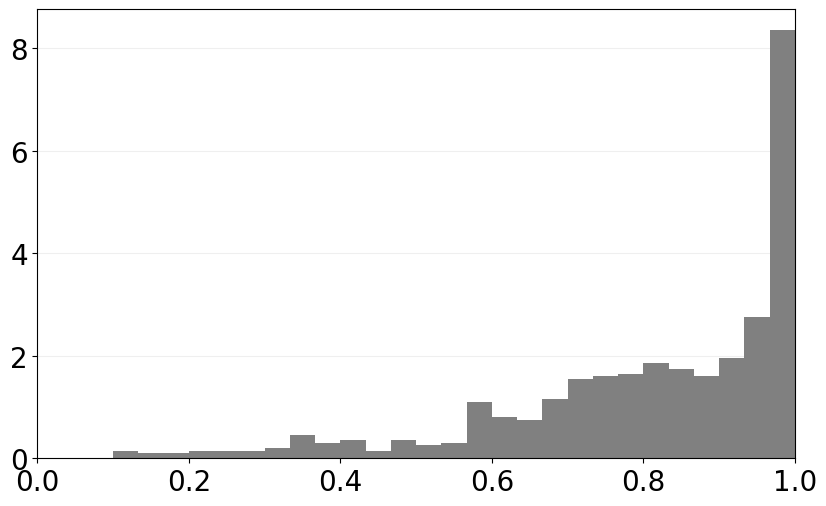

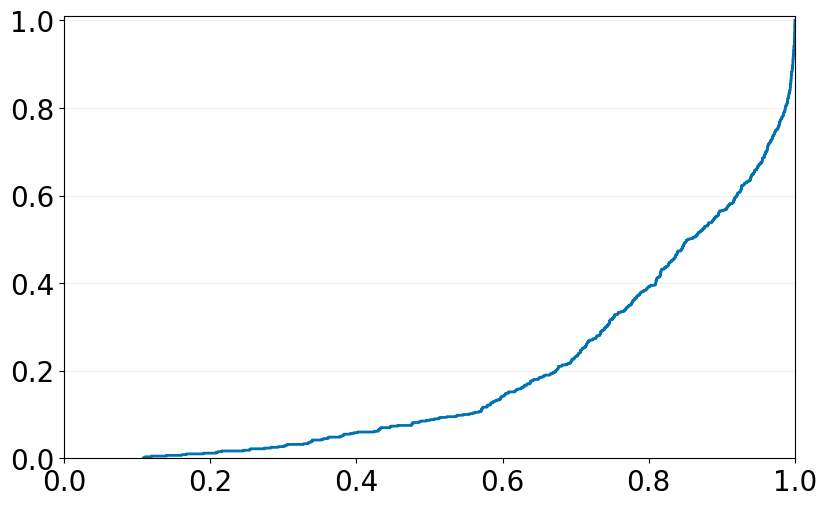

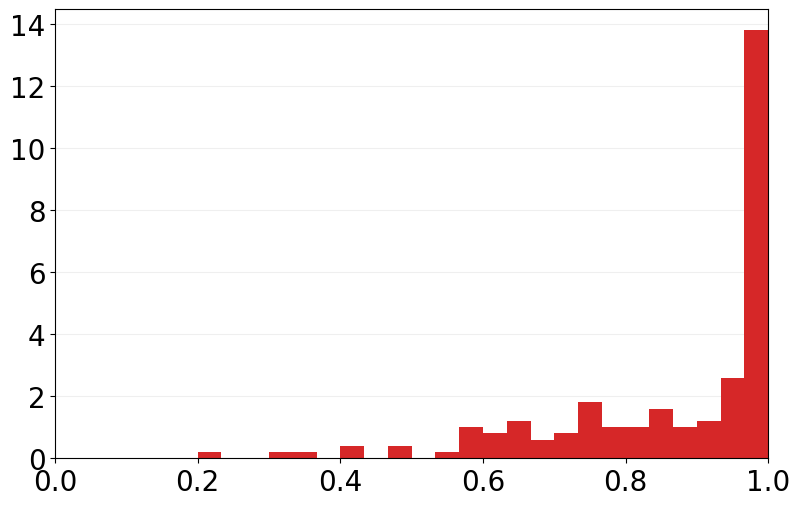

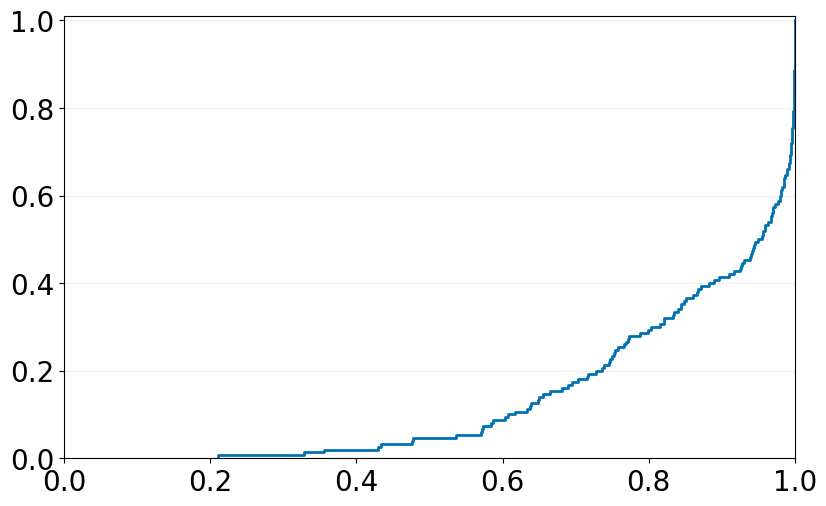

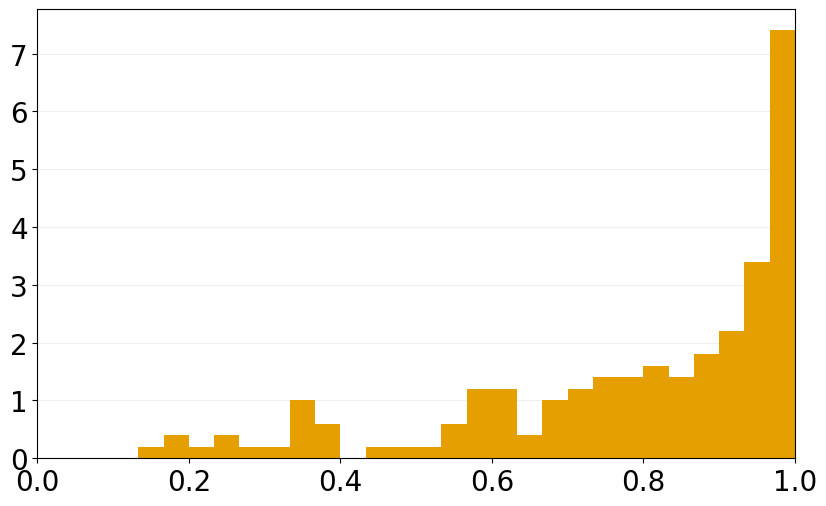

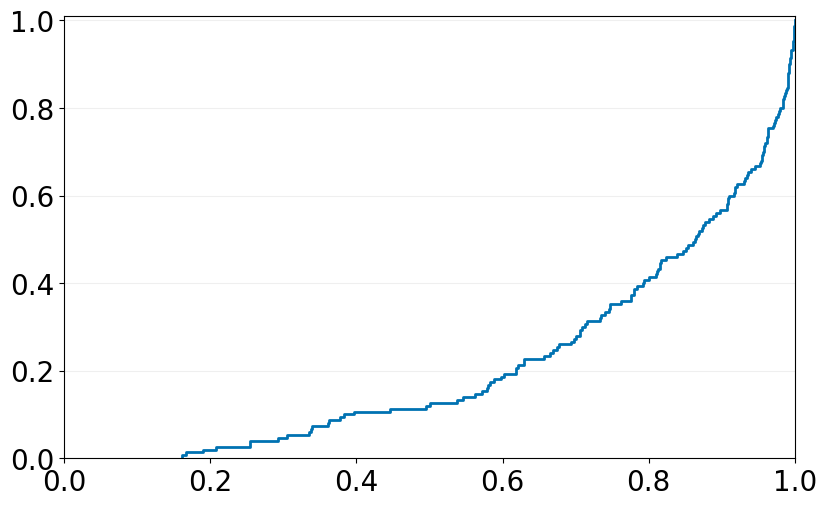

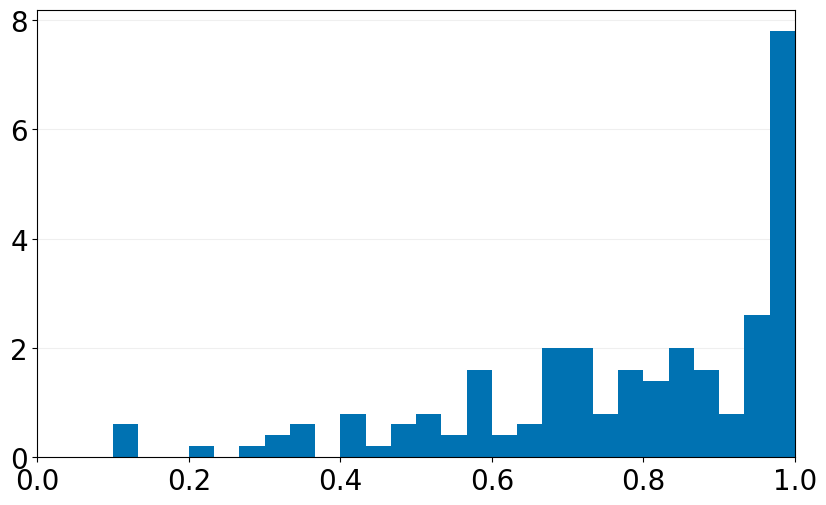

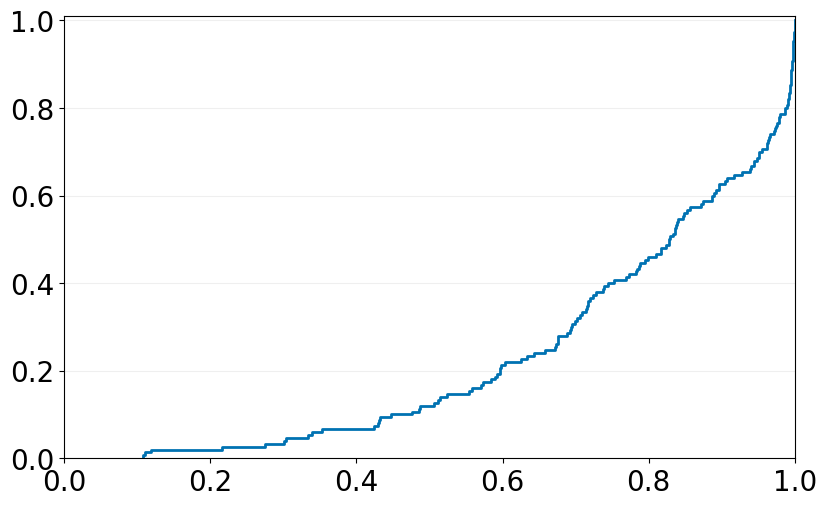

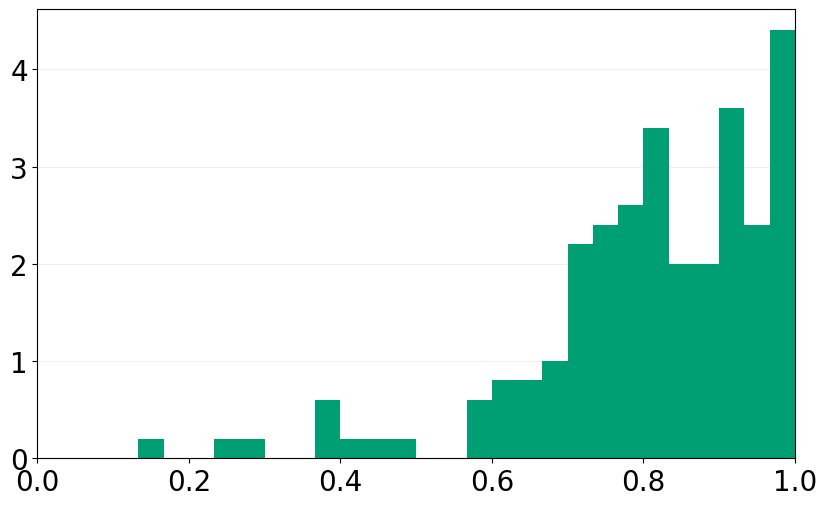

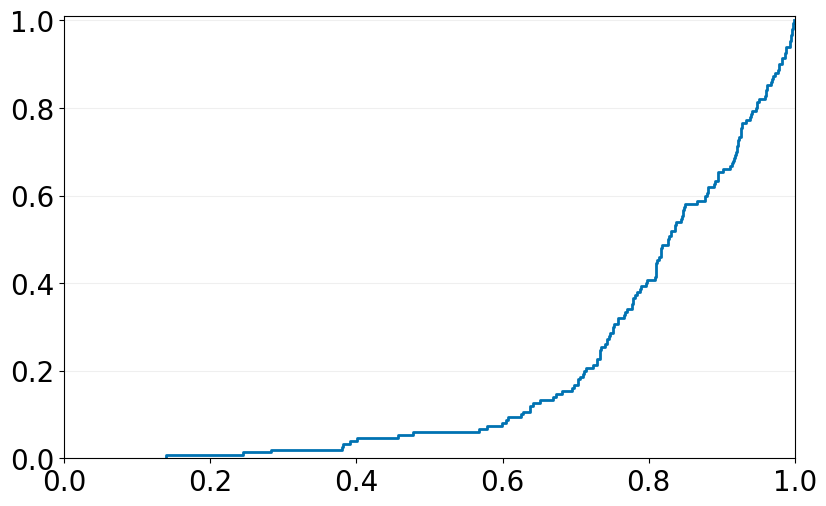

Creating separate PDFs and CDFs for RMSE (rad)...


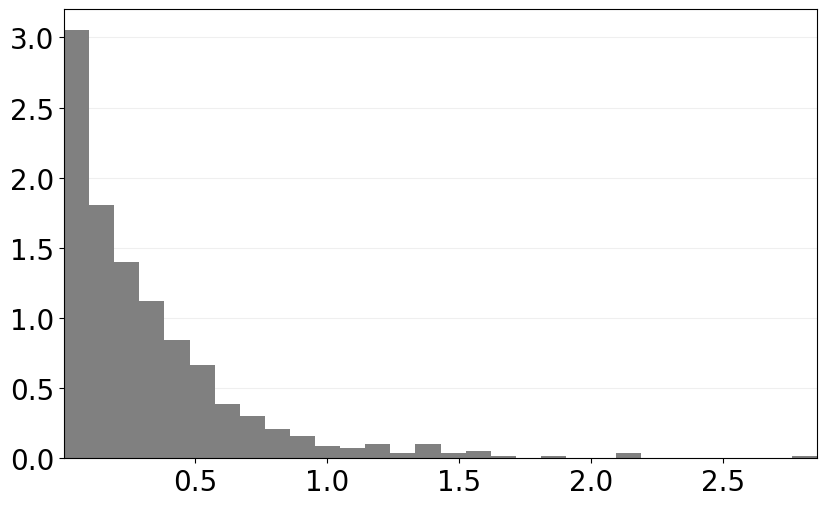

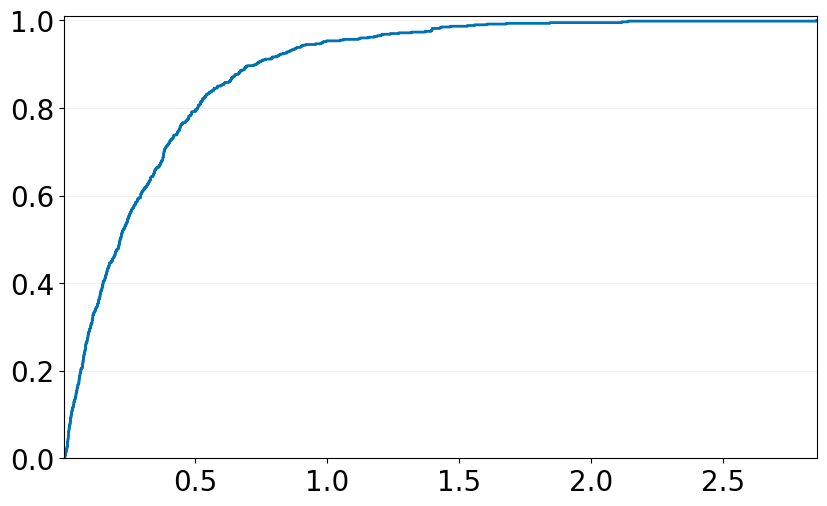

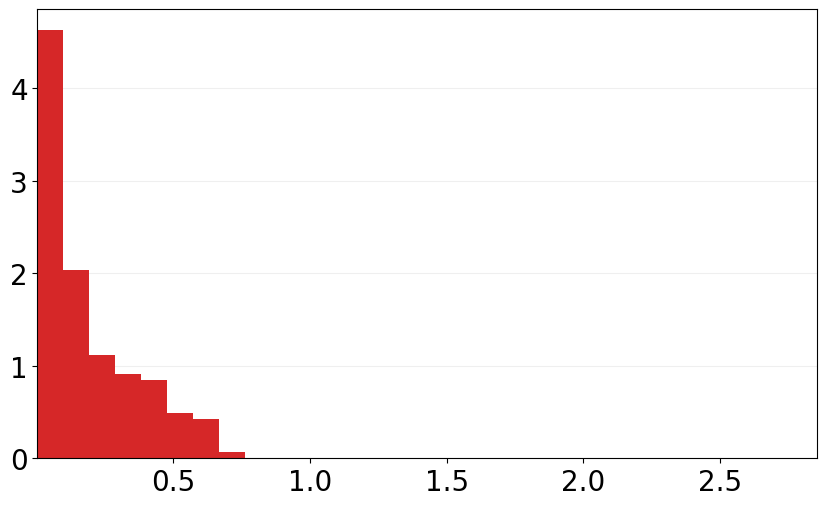

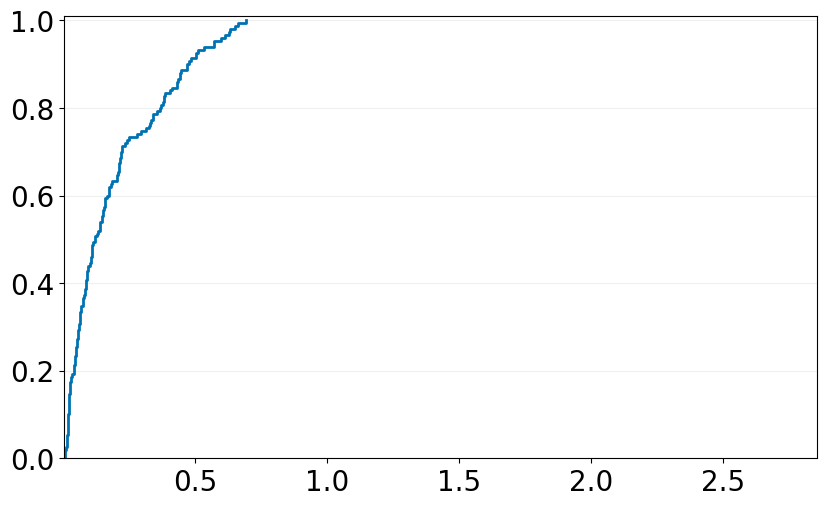

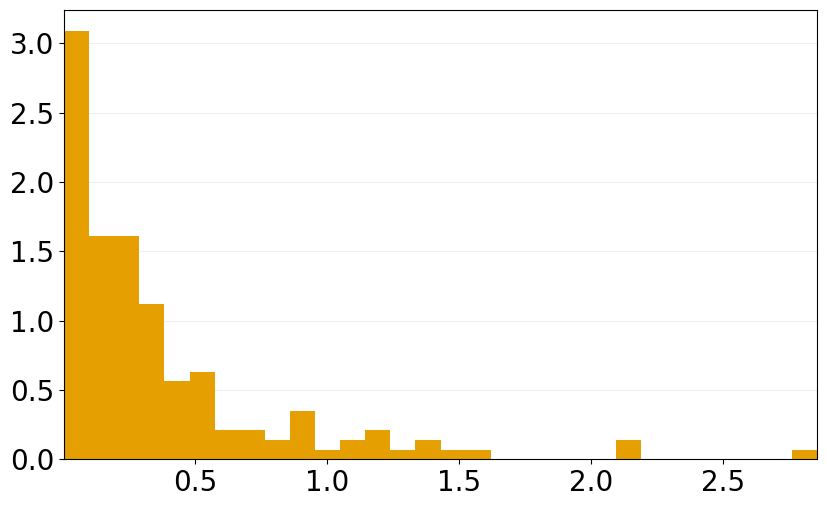

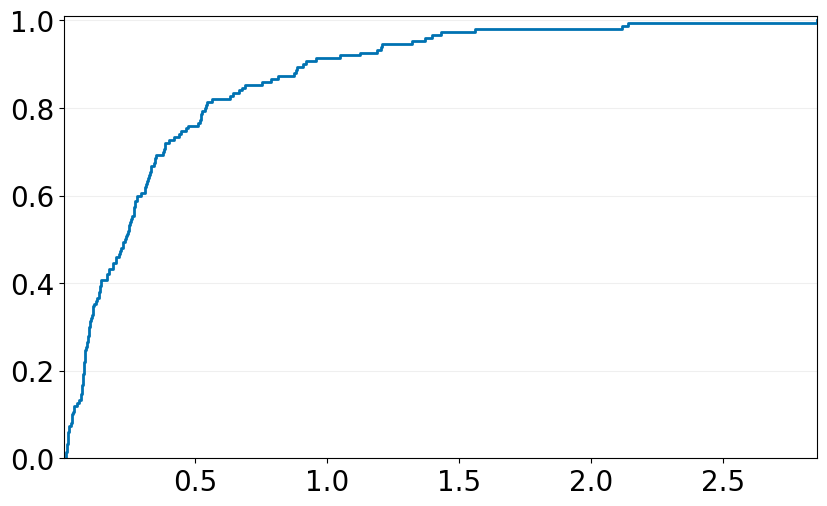

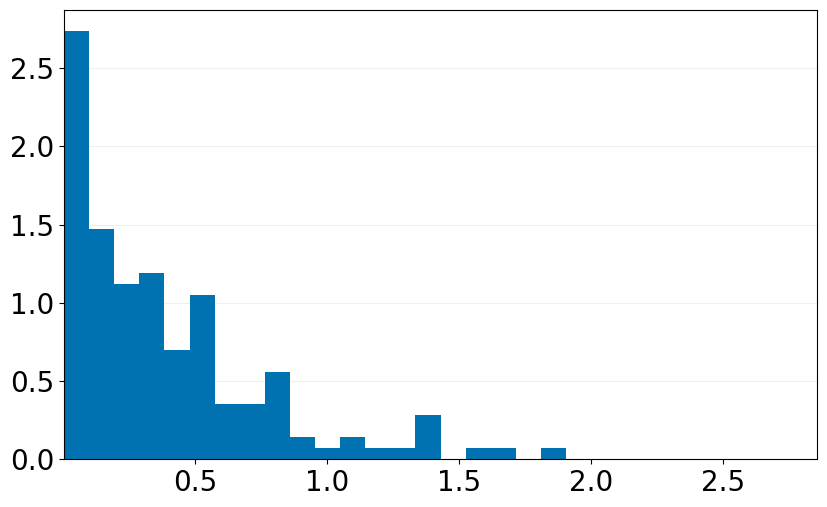

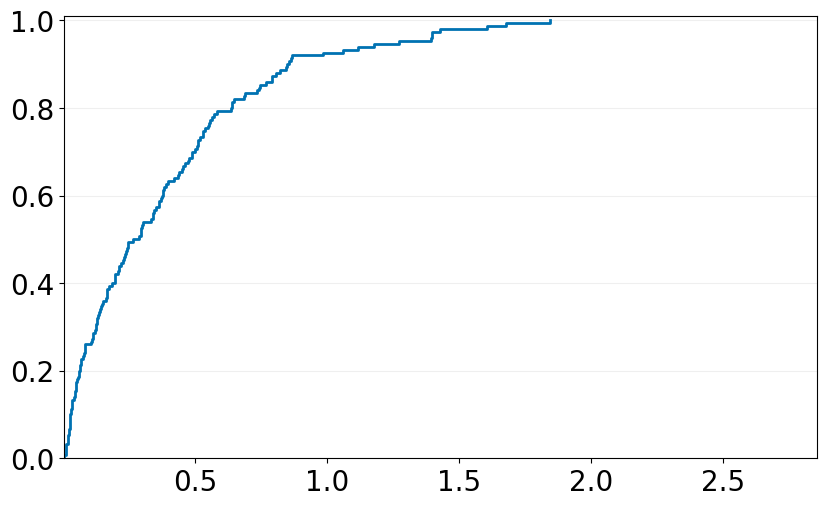

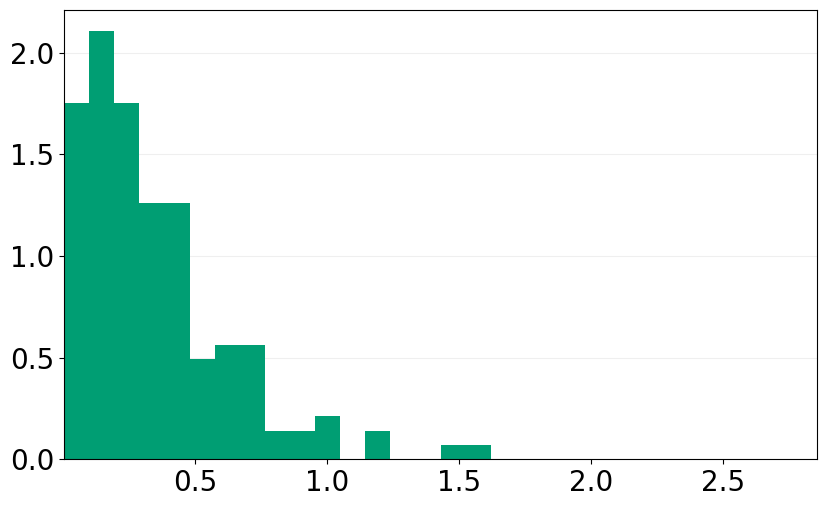

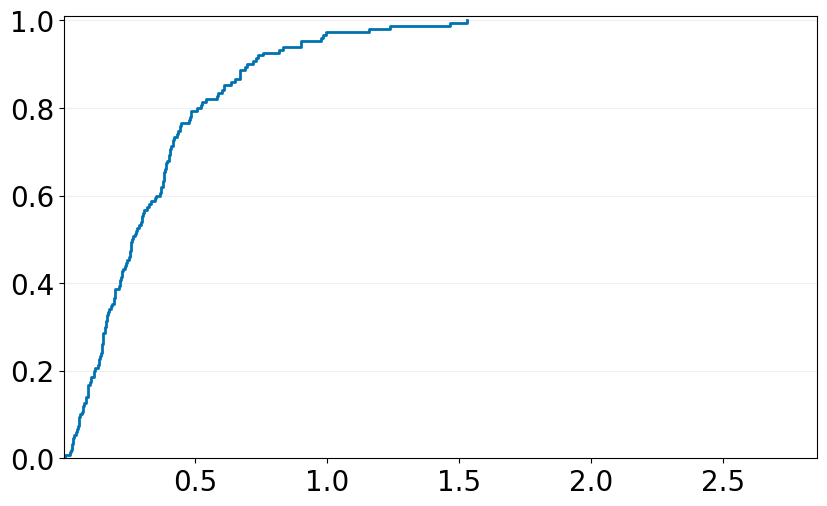

Creating separate PDFs and CDFs for Maximum absolute error (rad)...


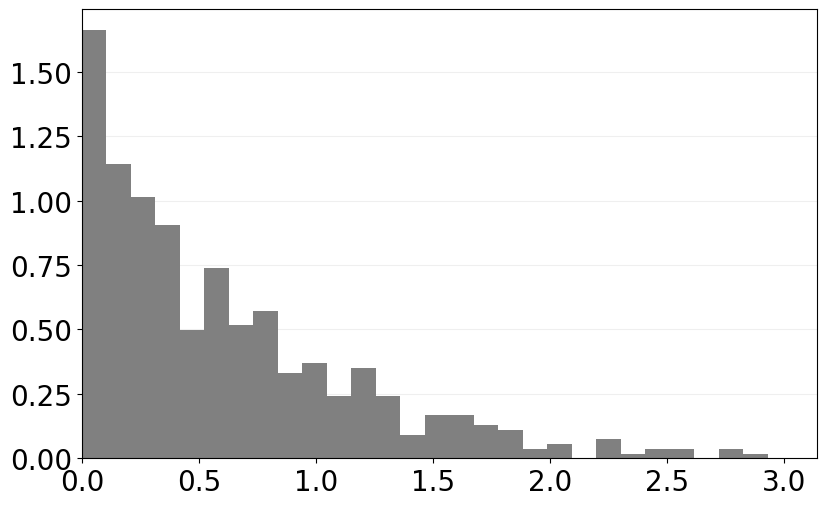

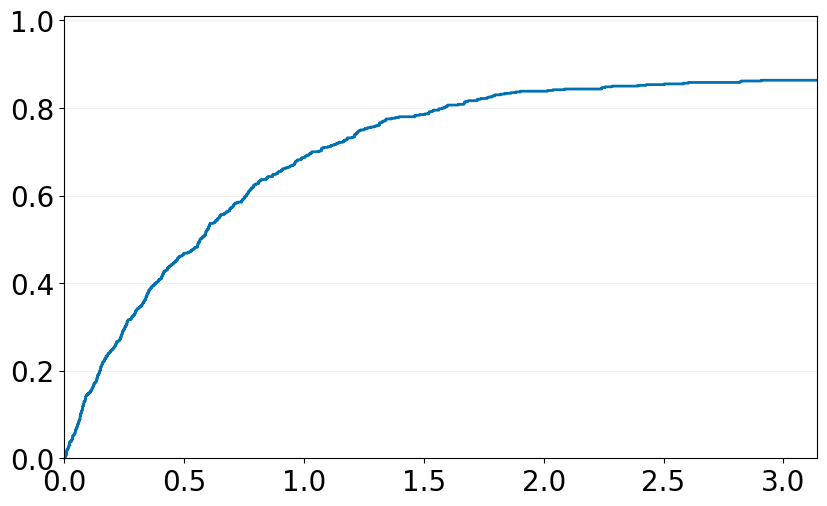

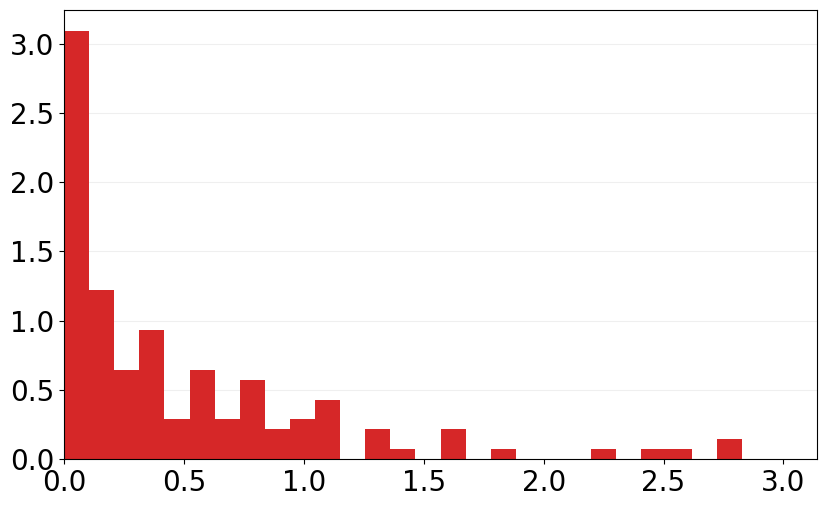

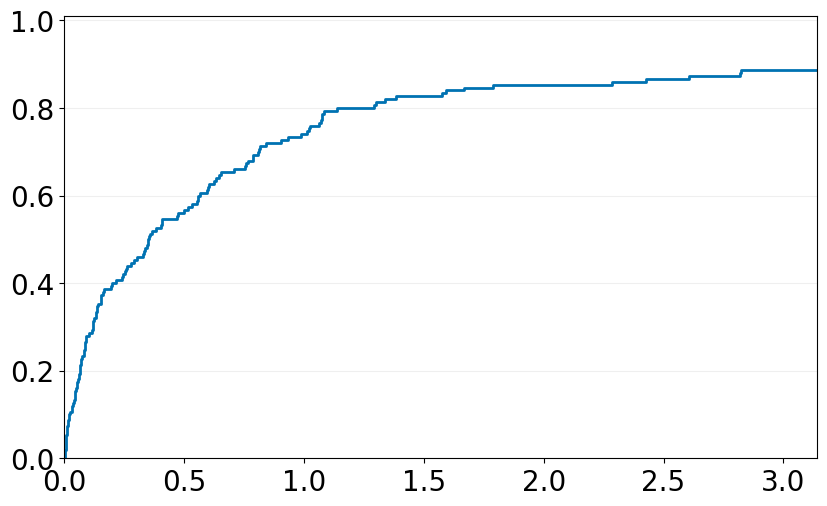

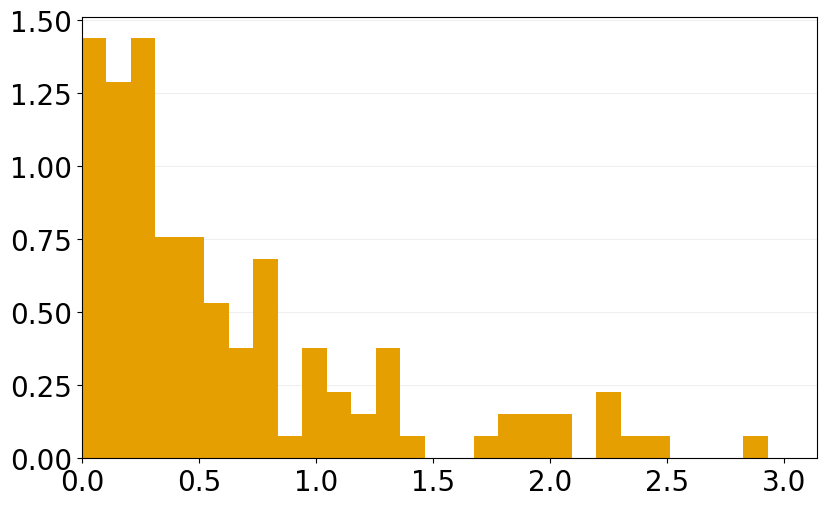

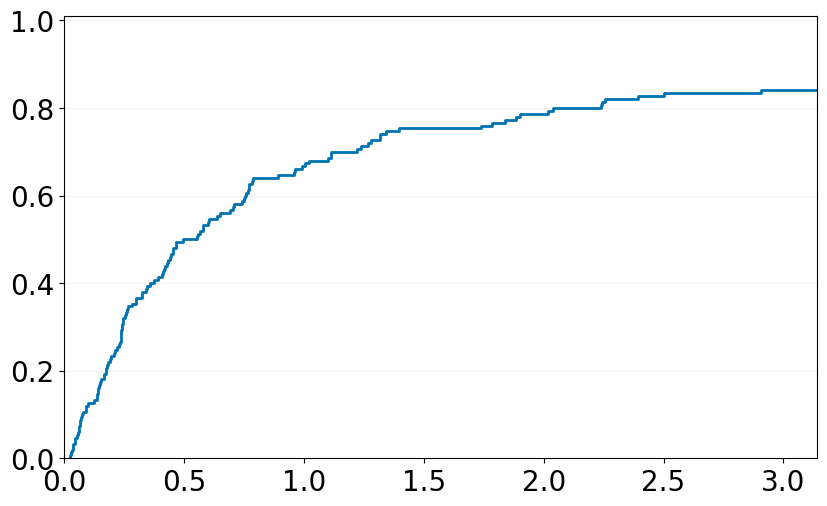

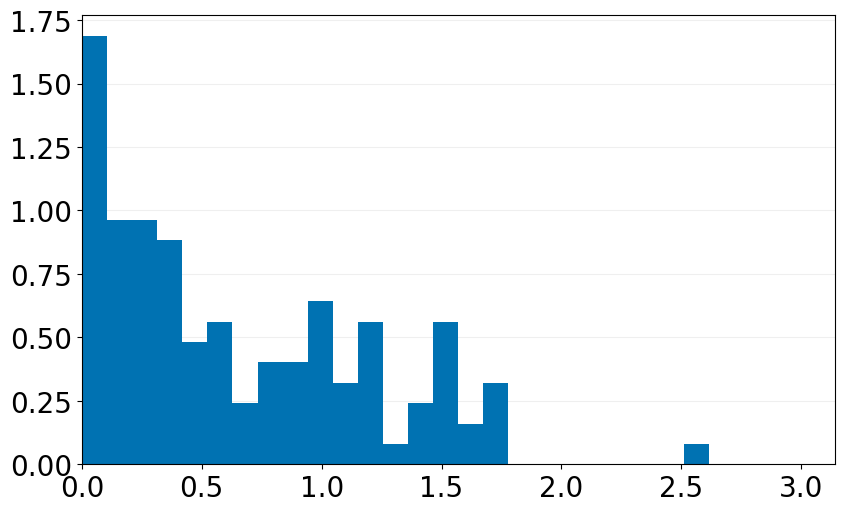

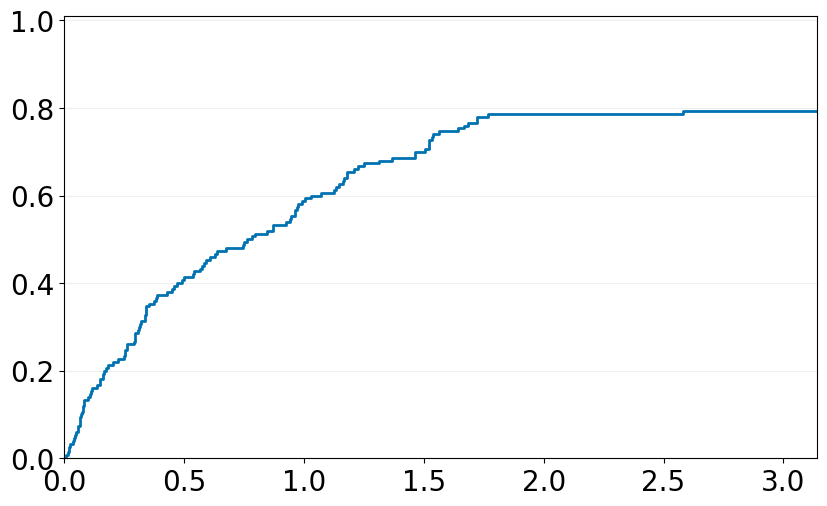

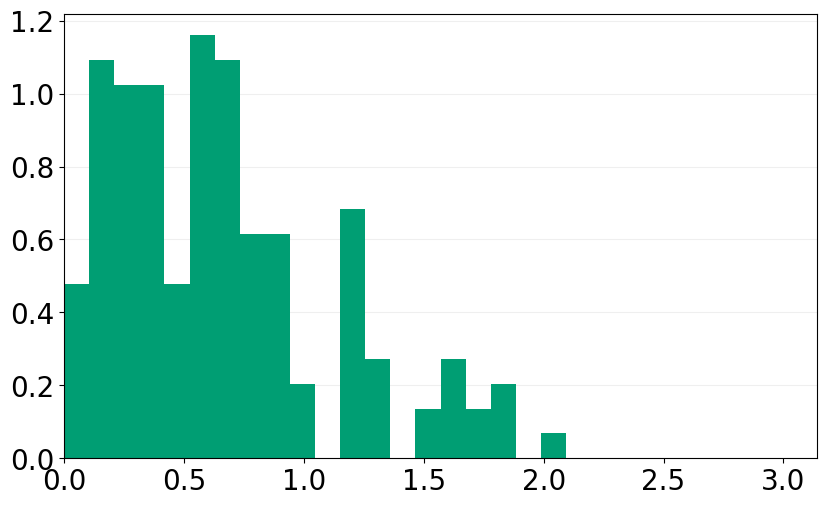

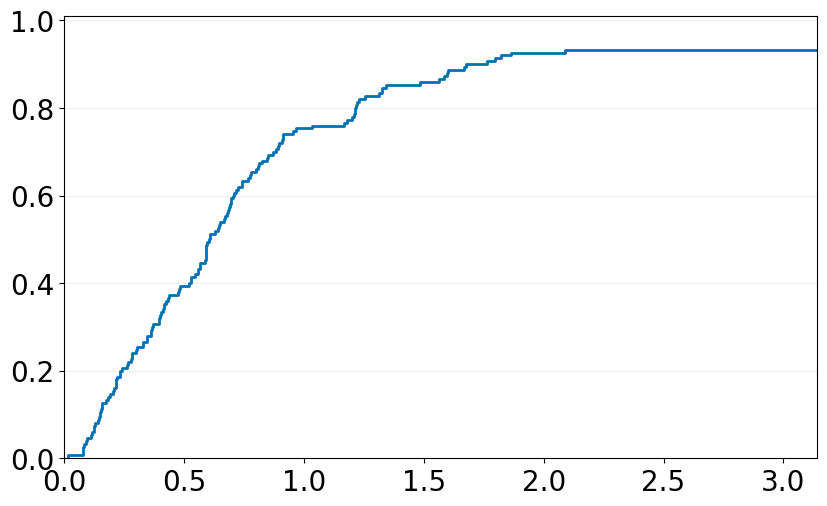

Creating separate PDFs and CDFs for Signal-to-error ratio (dB)...


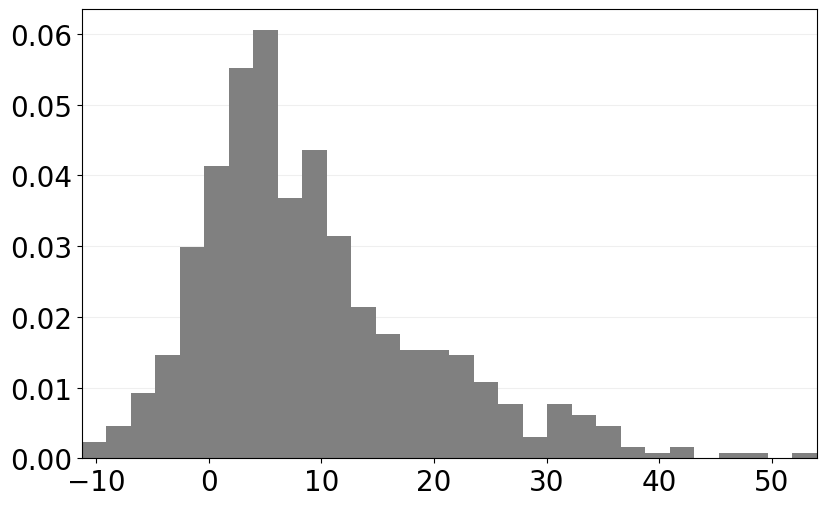

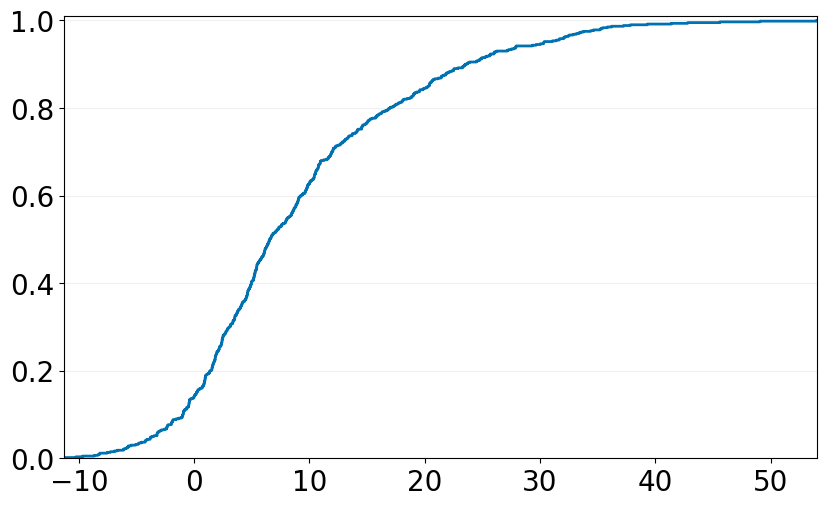

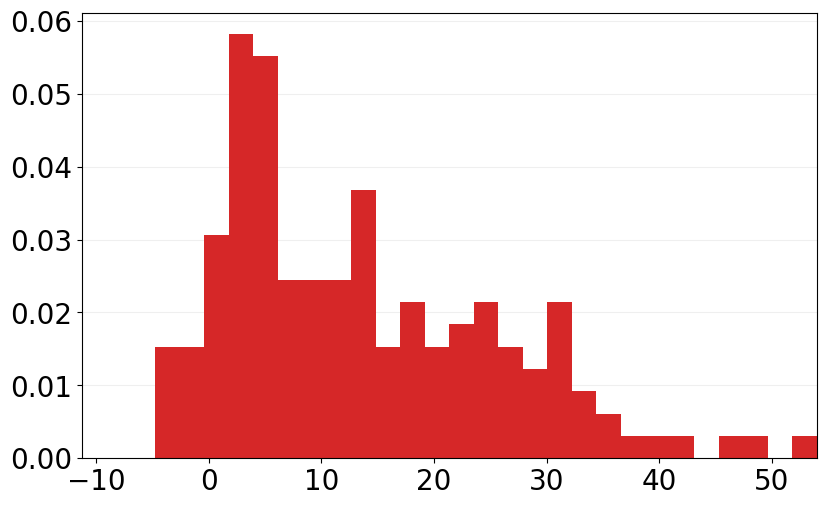

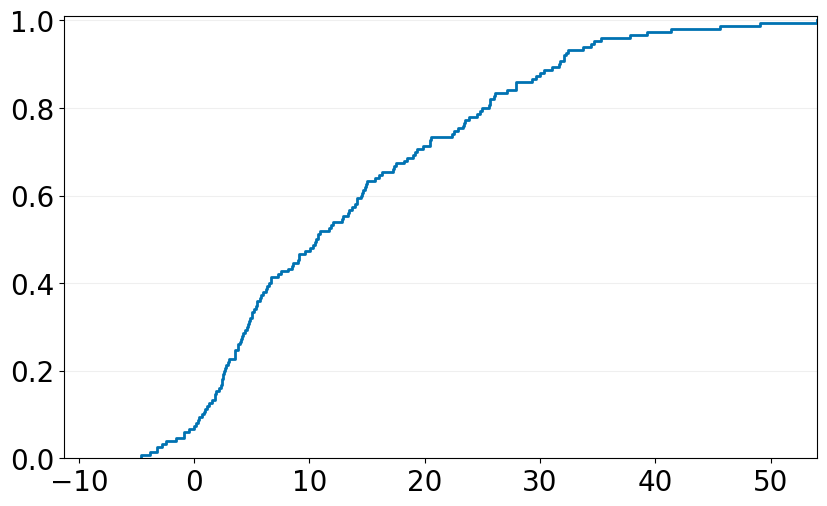

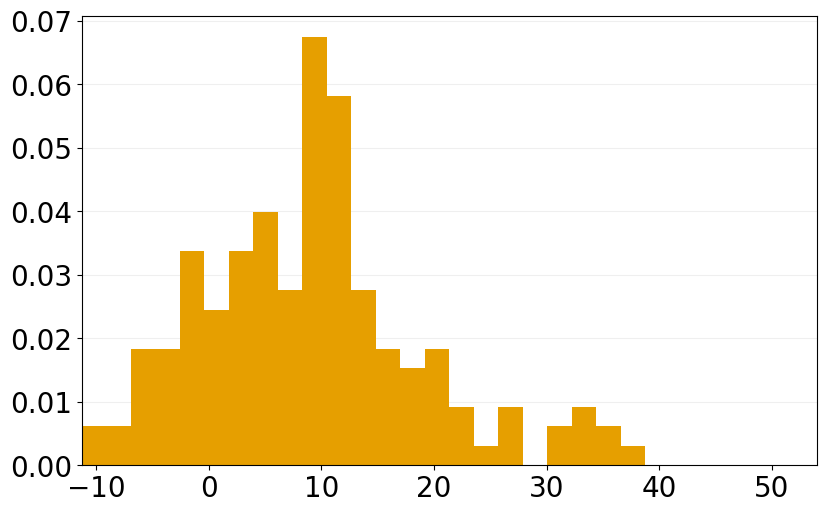

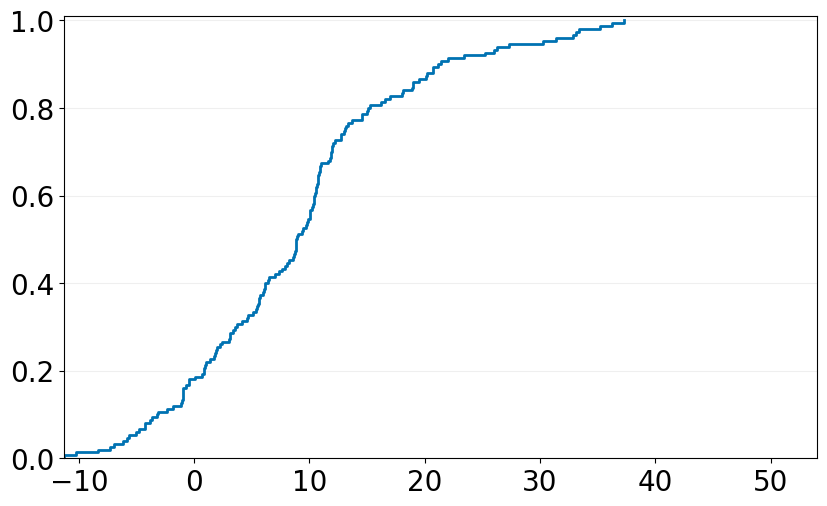

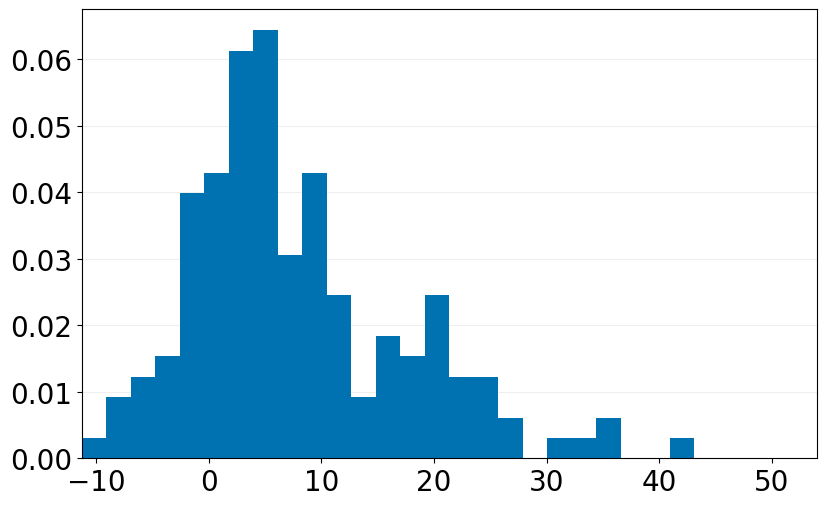

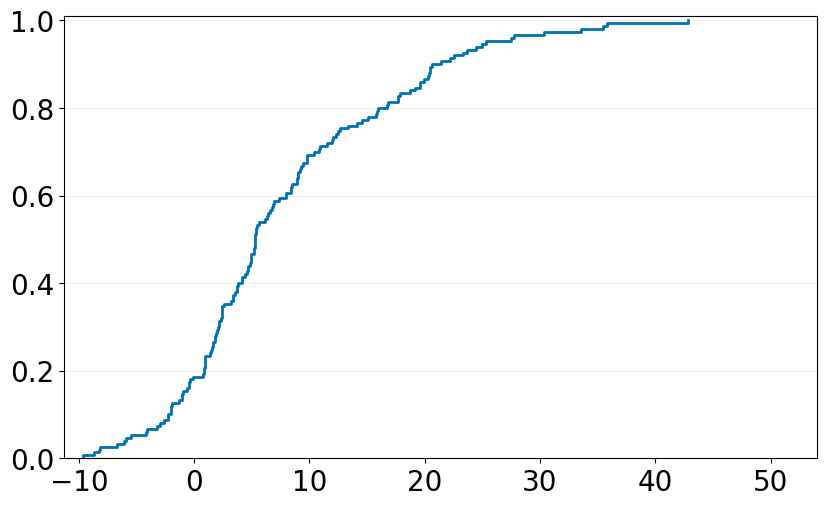

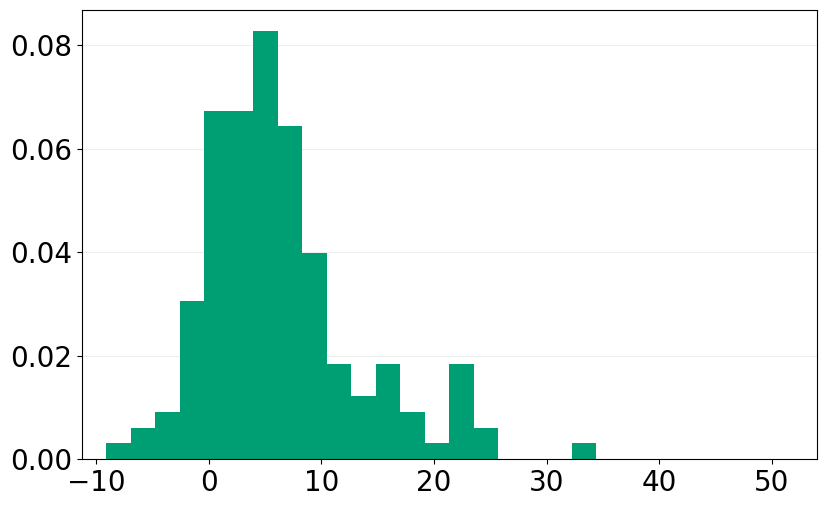

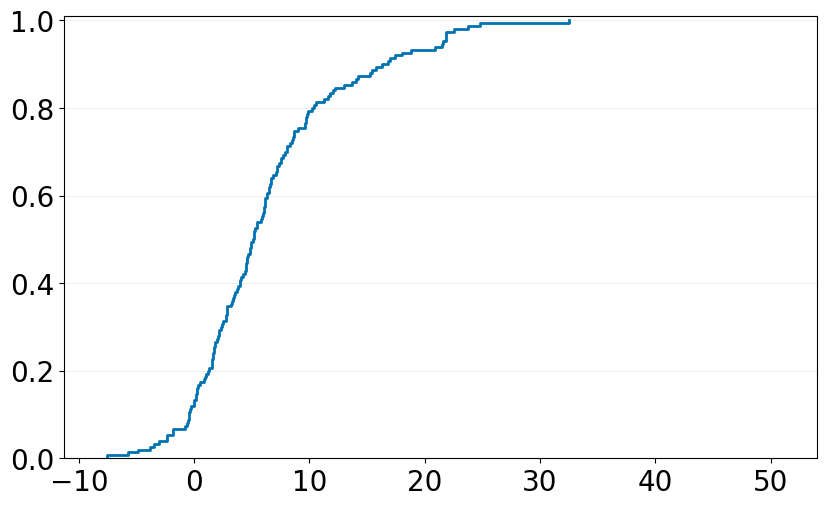

In [51]:
plot_results = {}
for metric, spec in METRIC_SPECS.items():
    print(f"Creating separate PDFs and CDFs for {spec['x_label']}...")
    metric_bin_edges = shared_bin_edges(
        source_metrics[metric].to_numpy(dtype=float), spec
    )
    metric_results = {
        'overall_pdf': plot_metric_pdf(
            source_metrics, metric, metric_bin_edges
        ),
        'overall_cdf': plot_metric_cdf(
            source_metrics, metric, metric_bin_edges
        ),
    }
    for family in FAMILY_ORDER:
        metric_results[f'{family}_pdf'] = plot_metric_pdf(
            source_metrics, metric, metric_bin_edges, family=family
        )
        metric_results[f'{family}_cdf'] = plot_metric_cdf(
            source_metrics, metric, metric_bin_edges, family=family
        )
    plot_results[metric] = metric_results

## Verify generated outputs

In [52]:
expected_plot_keys = {'overall_pdf', 'overall_cdf'} | {
    f'{family}_{plot_type}'
    for family in FAMILY_ORDER
    for plot_type in ('pdf', 'cdf')
}
expected_figure_count = len(METRIC_SPECS) * len(expected_plot_keys)
expected_file_count = expected_figure_count * len(EXPORT_FORMATS)
verification_rows = []
all_output_paths = []

for metric, metric_results in plot_results.items():
    if set(metric_results) != expected_plot_keys:
        raise AssertionError(f'{metric} is missing one or more PDF/CDF plot variants')
    reference_edges = metric_results['overall_pdf']['bin_edges']
    if len(reference_edges) != BIN_COUNT + 1:
        raise AssertionError(f'{metric} does not have the configured number of PDF bins')

    for plot_key, result in metric_results.items():
        expected_legend_entries = 1
        if len(result['legend_labels']) != expected_legend_entries:
            raise AssertionError(
                f"{metric}/{plot_key} has {len(result['legend_labels'])} legend entries; "
                f'expected {expected_legend_entries}'
            )
        if not np.array_equal(result['bin_edges'], reference_edges):
            raise AssertionError(f'{metric}/{plot_key} does not use the shared x-axis limits')

        for output_path in result['output_paths']:
            all_output_paths.append(output_path)
            if not output_path.is_file() or output_path.stat().st_size == 0:
                raise AssertionError(f'Missing or empty output: {output_path}')

        verification_rows.append({
            'metric': METRIC_SPECS[metric]['x_label'],
            'plot': plot_key,
            'scale': result['scale'],
            'bins': BIN_COUNT if result['plot_type'] == 'pdf' else 'ECDF',
            'legend_entries': len(result['legend_labels']),
            'exports': ', '.join(path.name for path in result['output_paths']),
        })

if len(all_output_paths) != expected_file_count:
    raise AssertionError(
        f'Generated {len(all_output_paths)} files; expected {expected_file_count}'
    )

verification_table = pd.DataFrame(verification_rows)
display(verification_table)
print(f'Verified {len(source_metrics)} finite source observations.')
print(f'Verified {expected_figure_count} figures and {len(all_output_paths)} nonempty exports.')
print('Figure output directory:', OUTPUT_DIR)

,metric,plot,scale,bins,legend_entries,exports
0,Absolute correlation,overall_pdf,linear,30,1,"abs_correlation_overall_pdf.png, abs_correlati..."
1,Absolute correlation,overall_cdf,linear,ECDF,1,"abs_correlation_overall_cdf.png, abs_correlati..."
2,Absolute correlation,harmonic_pdf,linear,30,1,"abs_correlation_harmonic_pdf.png, abs_correlat..."
3,Absolute correlation,harmonic_cdf,linear,ECDF,1,"abs_correlation_harmonic_cdf.png, abs_correlat..."
4,Absolute correlation,filtered_noise_pdf,linear,30,1,"abs_correlation_filtered_noise_pdf.png, abs_co..."
5,Absolute correlation,filtered_noise_cdf,linear,ECDF,1,"abs_correlation_filtered_noise_cdf.png, abs_co..."
6,Absolute correlation,chirp_modulated_pdf,linear,30,1,"abs_correlation_chirp_modulated_pdf.png, abs_c..."
7,Absolute correlation,chirp_modulated_cdf,linear,ECDF,1,"abs_correlation_chirp_modulated_cdf.png, abs_c..."
8,Absolute correlation,piecewise_transient_pdf,linear,30,1,"abs_correlation_piecewise_transient_pdf.png, a..."
9,Absolute correlation,piecewise_transient_cdf,linear,ECDF,1,"abs_correlation_piecewise_transient_cdf.png, a..."


Verified 600 finite source observations.
Verified 40 figures and 80 nonempty exports.
Figure output directory: notebooks/artifacts/rss_validation/formal_experiments/paper_plots


## Plot true sources and cumulative body-fixed signals for one case

Edit `SOURCE_BODY_CASE_ID` to select any formal experimental case. This cell creates one figure containing the three true sources and a separate figure containing the three cumulative body-fixed observer signals. The figures intentionally have no title or axis labels.

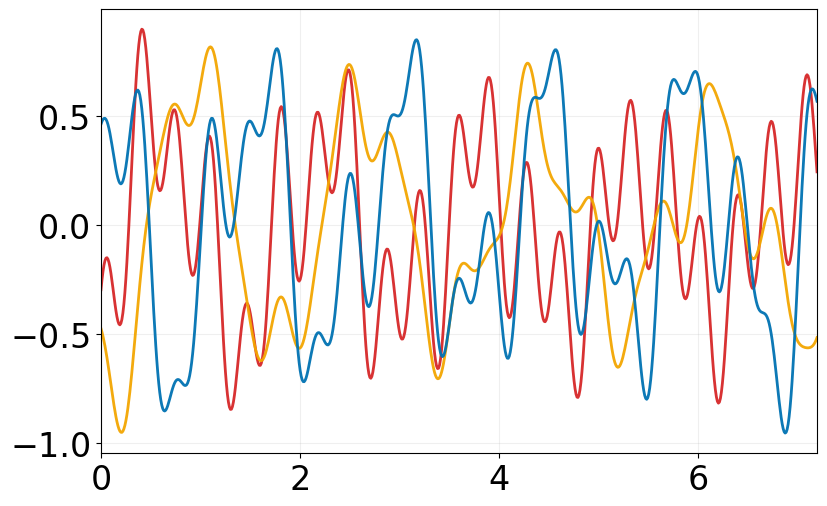

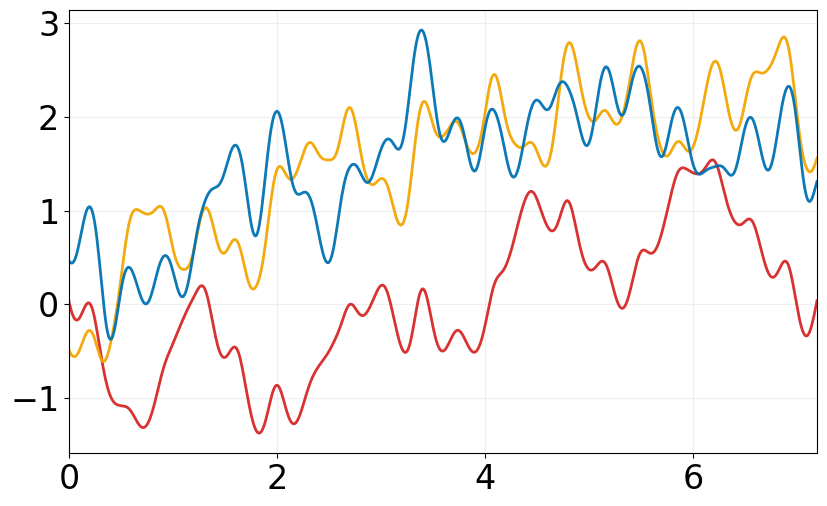

Selected case: notebooks/artifacts/rss_validation/standard_families/cases/harmonic/harmonic_05
True-source exports: ['harmonic_05_true_sources.png', 'harmonic_05_true_sources.pdf']
Cumulative body-fixed exports: ['harmonic_05_cumulative_body_fixed_signals.png', 'harmonic_05_cumulative_body_fixed_signals.pdf']


In [53]:
# Select any case directory name under formal_experiments/cases/.

EXPERIMENT_ROOT = REPO_ROOT / "notebooks/artifacts/rss_validation/standard_families"

SOURCE_BODY_CASE_ID = "harmonic_05"

SOURCE_BODY_LINE_WIDTH = 2.0
SOURCE_BODY_LINE_ALPHA = 0.95
SOURCE_BODY_COLORS = ("#D62728", "#F3A601", "#0072B2")

# Font size of the numerical values on the x- and y-axes
SOURCE_BODY_AXIS_FONT_SIZE = 24

SHOW_SOURCE_BODY_LEGEND = False
SOURCE_BODY_LEGEND_LOCATION = "best"


# ----------------------------------------------------------------------
# Find the selected experimental case
# ----------------------------------------------------------------------

case_matches = sorted(
    (EXPERIMENT_ROOT / "cases").glob(f"*/{SOURCE_BODY_CASE_ID}")
)

if len(case_matches) != 1:
    available_case_ids = sorted(
        path.name
        for path in (EXPERIMENT_ROOT / "cases").glob("*/*")
    )

    raise FileNotFoundError(
        f"Expected one case named {SOURCE_BODY_CASE_ID!r}, "
        f"found {len(case_matches)}. "
        f"Example available cases: {available_case_ids[:8]}"
    )

source_body_case_dir = case_matches[0]


# ----------------------------------------------------------------------
# Load data
# ----------------------------------------------------------------------

source_comparison = pd.read_csv(
    source_body_case_dir / "source_comparison.csv"
)

cumulative_body_fixed = pd.read_csv(
    source_body_case_dir / "observed_signals.csv"
)

true_source_columns = [
    f"true_source_{index}"
    for index in range(1, 4)
]

body_fixed_columns = [
    f"observer_{index}"
    for index in range(1, 4)
]


# ----------------------------------------------------------------------
# Validate data
# ----------------------------------------------------------------------

for frame, required in (
    (
        source_comparison,
        {"time_seconds", *true_source_columns},
    ),
    (
        cumulative_body_fixed,
        {"time_seconds", *body_fixed_columns},
    ),
):
    missing = sorted(required.difference(frame.columns))

    if missing:
        raise ValueError(
            f"{source_body_case_dir} is missing columns: {missing}"
        )

    if not np.isfinite(
        frame[list(required)].to_numpy(dtype=float)
    ).all():
        raise ValueError(
            f"{source_body_case_dir} contains non-finite plotting values"
        )


if not np.array_equal(
    source_comparison["time_seconds"].to_numpy(),
    cumulative_body_fixed["time_seconds"].to_numpy(),
):
    raise ValueError(
        "True-source and cumulative body-fixed time samples do not match"
    )


# ----------------------------------------------------------------------
# Plot the true source signals
# ----------------------------------------------------------------------

with plt.rc_context(plotting_rc_settings()):

    true_figure, true_axis = plt.subplots(
        figsize=FIGURE_SIZE
    )

    for index, (column, color) in enumerate(
        zip(true_source_columns, SOURCE_BODY_COLORS),
        start=1,
    ):
        true_axis.plot(
            source_comparison["time_seconds"],
            source_comparison[column],
            color=color,
            linewidth=SOURCE_BODY_LINE_WIDTH,
            alpha=SOURCE_BODY_LINE_ALPHA,
            label=f"Source {index}",
        )

    true_axis.margins(x=0)

    true_axis.grid(
        alpha=GRID_ALPHA,
        linewidth=0.8,
    )

    true_axis.set_axisbelow(True)

    # Adjust numerical axis-value font size
    true_axis.tick_params(
        axis="both",
        which="major",
        labelsize=SOURCE_BODY_AXIS_FONT_SIZE,
    )

    if SHOW_SOURCE_BODY_LEGEND:
        true_axis.legend(
            loc=SOURCE_BODY_LEGEND_LOCATION,
            frameon=True,
            framealpha=0.95,
        )

    true_source_paths = save_and_display_figure(
        true_figure,
        f"{SOURCE_BODY_CASE_ID}_true_sources",
    )


    # ------------------------------------------------------------------
    # Plot the cumulative body-fixed observer signals
    # ------------------------------------------------------------------

    body_figure, body_axis = plt.subplots(
        figsize=FIGURE_SIZE
    )

    for index, (column, color) in enumerate(
        zip(body_fixed_columns, SOURCE_BODY_COLORS),
        start=1,
    ):
        body_axis.plot(
            cumulative_body_fixed["time_seconds"],
            cumulative_body_fixed[column],
            color=color,
            linewidth=SOURCE_BODY_LINE_WIDTH,
            alpha=SOURCE_BODY_LINE_ALPHA,
            label=f"Observer {index}",
        )

    body_axis.margins(x=0)

    body_axis.grid(
        alpha=GRID_ALPHA,
        linewidth=0.8,
    )

    body_axis.set_axisbelow(True)

    # Adjust numerical axis-value font size
    body_axis.tick_params(
        axis="both",
        which="major",
        labelsize=SOURCE_BODY_AXIS_FONT_SIZE,
    )

    if SHOW_SOURCE_BODY_LEGEND:
        body_axis.legend(
            loc=SOURCE_BODY_LEGEND_LOCATION,
            frameon=True,
            framealpha=0.95,
        )

    cumulative_body_fixed_paths = save_and_display_figure(
        body_figure,
        f"{SOURCE_BODY_CASE_ID}_cumulative_body_fixed_signals",
    )


# ----------------------------------------------------------------------
# Print exported files
# ----------------------------------------------------------------------

print("Selected case:", source_body_case_dir)

print(
    "True-source exports:",
    [path.name for path in true_source_paths],
)

print(
    "Cumulative body-fixed exports:",
    [path.name for path in cumulative_body_fixed_paths],
)

## Plot matched true-source and RSS-output pairs for one case

Edit `RECOVERY_CASE_ID` independently of the preceding selection. This cell creates three separate figures, one for each matched source/output pair. The true source is drawn as a dotted line above the solid RSS output, with no title or axis labels.

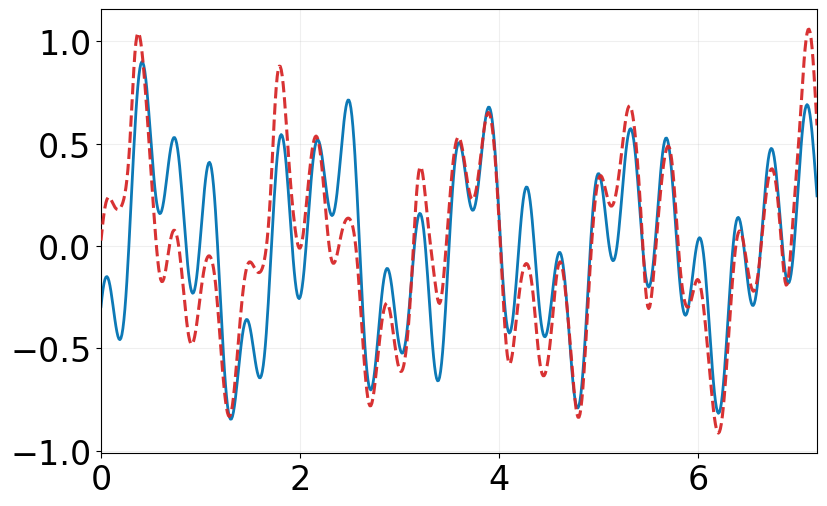

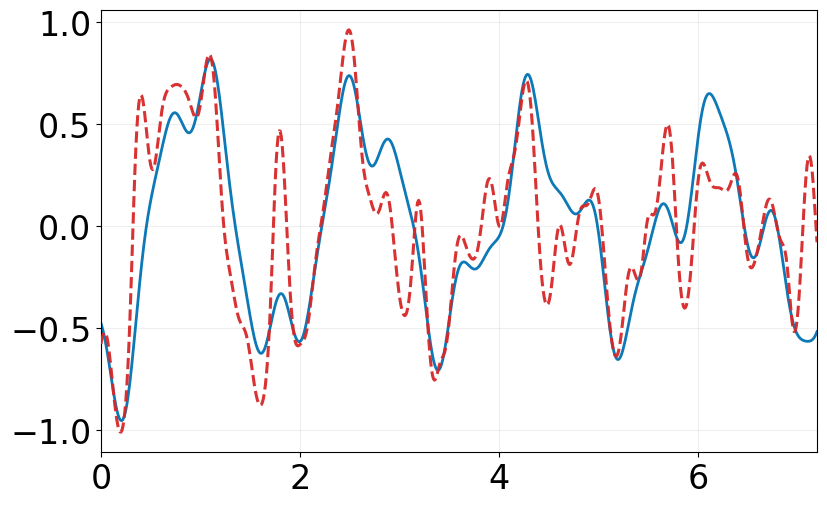

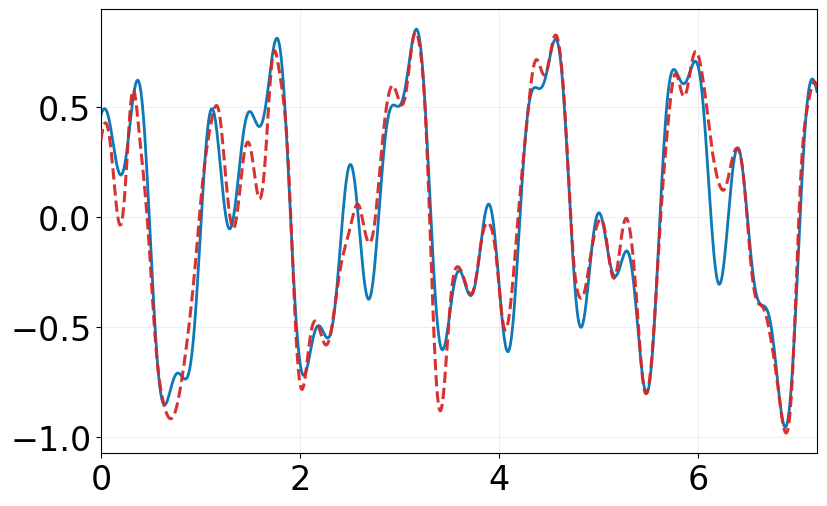

Selected case: notebooks/artifacts/rss_validation/standard_families/cases/harmonic/harmonic_05
Matched source/RSS exports: ['harmonic_05_source_1_rss_comparison.png', 'harmonic_05_source_1_rss_comparison.pdf', 'harmonic_05_source_2_rss_comparison.png', 'harmonic_05_source_2_rss_comparison.pdf', 'harmonic_05_source_3_rss_comparison.png', 'harmonic_05_source_3_rss_comparison.pdf']


In [54]:
# Select any case directory name under formal_experiments/cases/.

RECOVERY_CASE_ID = "harmonic_05"

RSS_OUTPUT_COLOR = "#D62728"
TRUE_SOURCE_COLOR = "#0072B2"

RSS_OUTPUT_LINE_WIDTH = 2.2
TRUE_SOURCE_LINE_WIDTH = 2.0
RECOVERY_LINE_ALPHA = 0.95

SHOW_RECOVERY_LEGEND = False
RECOVERY_LEGEND_LOCATION = "best"

# Font size of the numerical values on the x- and y-axes
RECOVERY_TICK_FONT_SIZE = 24


# ----------------------------------------------------------------------
# Find the selected experimental case
# ----------------------------------------------------------------------

case_matches = sorted(
    (EXPERIMENT_ROOT / "cases").glob(f"*/{RECOVERY_CASE_ID}")
)

if len(case_matches) != 1:

    available_case_ids = sorted(
        path.name
        for path in (EXPERIMENT_ROOT / "cases").glob("*/*")
    )

    raise FileNotFoundError(
        f"Expected one case named {RECOVERY_CASE_ID!r}, "
        f"found {len(case_matches)}. "
        f"Example available cases: {available_case_ids[:8]}"
    )

recovery_case_dir = case_matches[0]


# ----------------------------------------------------------------------
# Load source comparison data
# ----------------------------------------------------------------------

recovery_comparison = pd.read_csv(
    recovery_case_dir / "source_comparison.csv"
)


# ----------------------------------------------------------------------
# Validate required columns and plotting values
# ----------------------------------------------------------------------

required_columns = {"time_seconds"} | {
    f"{prefix}_{index}"
    for prefix in ("true_source", "rss_source")
    for index in range(1, 4)
}

missing_columns = sorted(
    required_columns.difference(recovery_comparison.columns)
)

if missing_columns:
    raise ValueError(
        f"{recovery_case_dir} is missing columns: {missing_columns}"
    )

if not np.isfinite(
    recovery_comparison[list(required_columns)].to_numpy(dtype=float)
).all():
    raise ValueError(
        f"{recovery_case_dir} contains non-finite plotting values"
    )


# ----------------------------------------------------------------------
# Plot RSS recovery results for each source
# ----------------------------------------------------------------------

recovery_export_paths = []

with plt.rc_context(plotting_rc_settings()):

    for source_index in range(1, 4):

        figure, axis = plt.subplots(
            figsize=FIGURE_SIZE
        )

        # Ground-truth source
        axis.plot(
            recovery_comparison["time_seconds"],
            recovery_comparison[f"true_source_{source_index}"],
            color=TRUE_SOURCE_COLOR,
            linestyle="-",
            linewidth=TRUE_SOURCE_LINE_WIDTH,
            alpha=RECOVERY_LINE_ALPHA,
            label="True source",
            zorder=2,
        )

        # RSS recovered source
        axis.plot(
            recovery_comparison["time_seconds"],
            recovery_comparison[f"rss_source_{source_index}"],
            color=RSS_OUTPUT_COLOR,
            linestyle="--",
            linewidth=RSS_OUTPUT_LINE_WIDTH,
            alpha=RECOVERY_LINE_ALPHA,
            label="RSS output",
            zorder=3,
        )

        axis.margins(x=0)

        axis.grid(
            alpha=GRID_ALPHA,
            linewidth=0.8,
        )

        axis.set_axisbelow(True)

        # Adjust numerical x- and y-axis font size
        axis.tick_params(
            axis="both",
            which="major",
            labelsize=RECOVERY_TICK_FONT_SIZE,
        )

        if SHOW_RECOVERY_LEGEND:
            axis.legend(
                loc=RECOVERY_LEGEND_LOCATION,
                frameon=True,
                framealpha=0.95,
            )

        recovery_export_paths.extend(
            save_and_display_figure(
                figure,
                f"{RECOVERY_CASE_ID}_source_{source_index}_rss_comparison",
            )
        )


# ----------------------------------------------------------------------
# Print exported files
# ----------------------------------------------------------------------

print(
    "Selected case:",
    recovery_case_dir,
)

print(
    "Matched source/RSS exports:",
    [path.name for path in recovery_export_paths],
)

In [55]:
# ----------------------------------------------------------------------
# Distribution statistics:
# absolute correlation and RAW angular RMSE
# ----------------------------------------------------------------------

DISTRIBUTION_METRICS = {
    "true_rss_abs_correlation": "Absolute correlation",
    "source_rmse_rad": "RMSE (rad)",
}

distribution_summary_rows = []


# Overall + individual signal families
distribution_groups = [
    (
        "Overall",
        source_metrics,
    )
] + [
    (
        FAMILY_LABELS[family],
        source_metrics.loc[
            source_metrics["family"] == family
        ],
    )
    for family in FAMILY_ORDER
]


for group_name, group_frame in distribution_groups:

    for metric_column, metric_label in DISTRIBUTION_METRICS.items():

        values = (
            group_frame[
                metric_column
            ]
            .dropna()
        )

        distribution_summary_rows.append({
            "Group": group_name,
            "Metric": metric_label,
            "N": len(values),
            "Mean": values.mean(),
            "Standard deviation": values.std(ddof=1),
            "Skewness": values.skew(),
            "Kurtosis": values.kurt(),
        })


distribution_statistics_table = pd.DataFrame(
    distribution_summary_rows
)


# ----------------------------------------------------------------------
# Display formatted table
# ----------------------------------------------------------------------

display(
    distribution_statistics_table.style.format({
        "Mean": "{:.4f}",
        "Standard deviation": "{:.4f}",
        "Skewness": "{:.4f}",
        "Kurtosis": "{:.4f}",
    })
)

,Group,Metric,N,Mean,Standard deviation,Skewness,Kurtosis
0,Overall,Absolute correlation,600,0.8089,0.1970,-1.2722,1.2592
1,Overall,RMSE (rad),600,0.3219,0.3468,2.4059,8.7125
2,Harmonic,Absolute correlation,150,0.8649,0.1701,-1.4066,1.5470
3,Harmonic,RMSE (rad),150,0.1894,0.1800,1.0825,0.1206
4,Filtered noise,Absolute correlation,150,0.7867,0.2208,-1.1614,0.5018
5,Filtered noise,RMSE (rad),150,0.3713,0.4482,2.5584,8.4184
6,Chirp modulated,Absolute correlation,150,0.7756,0.2182,-1.0382,0.5644
7,Chirp modulated,RMSE (rad),150,0.3835,0.3819,1.5471,2.4127
8,Piecewise transient,Absolute correlation,150,0.8083,0.1611,-1.4820,2.9300
9,Piecewise transient,RMSE (rad),150,0.3433,0.2829,1.6386,3.3551


## Selected-loss plots for zero-mean formal results

This section reads the consolidated zero-mean loss-comparison results, filters one user-selected loss function, and creates publication-ready source-level box plots, PDFs, CDFs, and distribution statistics. Existing analyses above remain unchanged.

### User-editable zero-mean plotting configuration

Change the selected loss method and any visual or export setting below, then rerun this section.

In [56]:
# Input selection and validation expectations.
ZERO_MEAN_RELATIVE_SOURCE_METRICS_PATH = Path(
    'outputs/rss_formal_loss_comparison_zero_mean/summary/per_source_metrics.csv'
)
ZERO_MEAN_SOURCE_METRICS_CSV = REPO_ROOT / ZERO_MEAN_RELATIVE_SOURCE_METRICS_PATH
ZERO_MEAN_OUTPUT_DIR = (
    REPO_ROOT / 'outputs/rss_formal_loss_comparison_zero_mean/plots'
)
ZERO_MEAN_SELECTED_LOSS_METHOD = 'zero_lag_cross_correlation'
ZERO_MEAN_LOSS_METHOD_LABELS = {
    'zero_lag_cross_correlation': 'Zero-lag correlation',
    'lagged_cross_correlation': 'Lagged correlation',
    'mutual_information': 'Mutual information',
    'action': 'Action',
}
ZERO_MEAN_EXPECTED_TOTAL_OBSERVATIONS = 600
ZERO_MEAN_EXPECTED_OBSERVATIONS_PER_FAMILY = 150
ZERO_MEAN_CORRELATION_TOLERANCE = 1e-12

# Metrics, labels, axis scales, limits, and collision-safe filenames.
# Set limits to None for data-derived limits; log scales require positive data.
ZERO_MEAN_METRIC_SPECS = {
    'true_rss_abs_correlation': {
        'title': 'absolute correlation',
        'axis_label': 'Absolute correlation',
        'scale': 'linear',
        'limits': (0.0, 1.05),
        'nonnegative': True,
        'file_stem': 'abs_correlation',
    },
    'source_rmse_rad': {
        'title': 'RMSE',
        'axis_label': 'RMSE (rad)',
        'scale': 'linear',
        'limits': (-0.05,),
        'nonnegative': True,
        'file_stem': 'rmse_rad',
    },
}
ZERO_MEAN_FILE_PREFIX = f'zero_mean_{ZERO_MEAN_SELECTED_LOSS_METHOD}_'
ZERO_MEAN_TITLE_CONTEXT = 'Zero-mean sources'

# Figure and export settings.
ZERO_MEAN_BOX_FIGURE_SIZE = (10.5, 5.5)
ZERO_MEAN_DISTRIBUTION_FIGURE_SIZE = (8.4, 5.2)
ZERO_MEAN_BIN_COUNT = 30
ZERO_MEAN_DENSITY = True
ZERO_MEAN_SHOW_SMOOTH_DENSITY = False
ZERO_MEAN_SMOOTH_DENSITY_POINTS = 512
ZERO_MEAN_SMOOTH_DENSITY_BANDWIDTH = 'scott'
ZERO_MEAN_PNG_DPI = 300
ZERO_MEAN_EXPORT_FORMATS = ('png', 'pdf')
ZERO_MEAN_SHOW_FIGURE_TITLE = False
ZERO_MEAN_SHOW_AXIS_LABELS = False
ZERO_MEAN_SHOW_LEGEND = False
ZERO_MEAN_SHOW_SAMPLE_COUNTS_IN_LEGEND = True
ZERO_MEAN_LEGEND_LOCATION = 'best'
ZERO_MEAN_LEGEND_COLUMNS = 0
ZERO_MEAN_GRID_ALPHA = 0.20

# Typography.
ZERO_MEAN_FONT_FAMILY = 'DejaVu Sans'
ZERO_MEAN_BASE_FONT_SIZE = 11
ZERO_MEAN_TITLE_FONT_SIZE = 13
ZERO_MEAN_AXIS_LABEL_FONT_SIZE = 12
ZERO_MEAN_TICK_LABEL_FONT_SIZE = 20
ZERO_MEAN_LEGEND_FONT_SIZE = 9

# Overall/family colors used consistently across box plots and PDFs.
ZERO_MEAN_SCOPE_COLORS = {
    'overall': '#808080',
    'harmonic': '#D62728',
    'filtered_noise': '#E69F00',
    'chirp_modulated': '#0072B2',
    'piecewise_transient': '#009E73',
}
ZERO_MEAN_CDF_COLOR = '#0072B2'
ZERO_MEAN_PDF_SMOOTH_COLOR = '#D62728'
ZERO_MEAN_HISTOGRAM_ALPHA = 1.0
ZERO_MEAN_HISTOGRAM_EDGE_COLOR = 'none'
ZERO_MEAN_CDF_LINE_WIDTH = 2.0
ZERO_MEAN_CDF_LINE_ALPHA = 1.0
ZERO_MEAN_SMOOTH_DENSITY_LINE_WIDTH = 1.8
ZERO_MEAN_SMOOTH_DENSITY_LINE_ALPHA = 1.0

# Box-plot appearance.
ZERO_MEAN_BOX_WIDTH = 0.50
ZERO_MEAN_BOX_WHISKERS = 1.5
ZERO_MEAN_BOX_SHOW_FLIERS = True
ZERO_MEAN_BOX_NOTCHED = False
ZERO_MEAN_BOX_SHOW_MEANS = False
ZERO_MEAN_BOX_ALPHA = 0.75
ZERO_MEAN_BOX_EDGE_COLOR = '#333333'
ZERO_MEAN_BOX_EDGE_LINE_WIDTH = 1.0
ZERO_MEAN_MEDIAN_COLOR = '#111111'
ZERO_MEAN_MEDIAN_LINE_WIDTH = 1.8
ZERO_MEAN_WHISKER_COLOR = '#555555'
ZERO_MEAN_WHISKER_LINE_WIDTH = 1.0
ZERO_MEAN_CAP_COLOR = '#555555'
ZERO_MEAN_CAP_LINE_WIDTH = 1.0
ZERO_MEAN_FLIER_MARKER = ''
ZERO_MEAN_FLIER_MARKER_SIZE = 3.0
ZERO_MEAN_FLIER_COLOR = '#555555'
ZERO_MEAN_FLIER_ALPHA = 0.55
ZERO_MEAN_MEAN_MARKER = 'D'
ZERO_MEAN_MEAN_MARKER_SIZE = 5.0
ZERO_MEAN_MEAN_COLOR = '#000000'
ZERO_MEAN_BOX_SHOW_X_TICKS = False
ZERO_MEAN_BOX_TICK_ROTATION = 90
ZERO_MEAN_BOX_TICK_HORIZONTAL_ALIGNMENT = 'right'

ZERO_MEAN_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Zero-mean input metrics:', ZERO_MEAN_SOURCE_METRICS_CSV)
print('Zero-mean figure output directory:', ZERO_MEAN_OUTPUT_DIR)

Zero-mean input metrics: outputs/rss_formal_loss_comparison_zero_mean/summary/per_source_metrics.csv
Zero-mean figure output directory: outputs/rss_formal_loss_comparison_zero_mean/plots


### Load, select, and validate the zero-mean results

In [57]:
if ZERO_MEAN_SELECTED_LOSS_METHOD not in ZERO_MEAN_LOSS_METHOD_LABELS:
    raise ValueError(
        'Unsupported ZERO_MEAN_SELECTED_LOSS_METHOD. Choose one of '
        f'{tuple(ZERO_MEAN_LOSS_METHOD_LABELS)}'
    )

if not ZERO_MEAN_SOURCE_METRICS_CSV.is_file():
    raise FileNotFoundError(
        f'Could not find zero-mean source metrics: {ZERO_MEAN_SOURCE_METRICS_CSV}'
    )

zero_mean_all_source_metrics = pd.read_csv(ZERO_MEAN_SOURCE_METRICS_CSV)
zero_mean_required_columns = {
    'family',
    'case_id',
    'source_index',
    'loss_method',
    'loss_display_name',
    *ZERO_MEAN_METRIC_SPECS,
}
zero_mean_missing_columns = sorted(
    zero_mean_required_columns.difference(zero_mean_all_source_metrics.columns)
)
if zero_mean_missing_columns:
    raise ValueError(
        f'Zero-mean metrics are missing required columns: {zero_mean_missing_columns}'
    )

zero_mean_observed_methods = set(
    zero_mean_all_source_metrics['loss_method'].dropna().astype(str).unique()
)
zero_mean_expected_methods = set(ZERO_MEAN_LOSS_METHOD_LABELS)
if zero_mean_observed_methods != zero_mean_expected_methods:
    raise ValueError(
        f'Expected loss methods {sorted(zero_mean_expected_methods)}, '
        f'observed {sorted(zero_mean_observed_methods)}'
    )

zero_mean_source_metrics = zero_mean_all_source_metrics.loc[
    zero_mean_all_source_metrics['loss_method']
    == ZERO_MEAN_SELECTED_LOSS_METHOD
].copy()

for metric in ZERO_MEAN_METRIC_SPECS:
    zero_mean_source_metrics[metric] = pd.to_numeric(
        zero_mean_source_metrics[metric],
        errors='raise',
    )
    metric_values = zero_mean_source_metrics[metric].to_numpy(dtype=float)
    if not np.isfinite(metric_values).all():
        raise ValueError(f'{metric} contains non-finite selected-loss values')

zero_mean_selected_families = set(
    zero_mean_source_metrics['family'].dropna().astype(str).unique()
)
if zero_mean_selected_families != set(FAMILY_ORDER):
    raise ValueError(
        f'Expected selected-loss families {sorted(FAMILY_ORDER)}, '
        f'observed {sorted(zero_mean_selected_families)}'
    )

zero_mean_duplicate_rows = zero_mean_source_metrics.duplicated(
    subset=['loss_method', 'family', 'case_id', 'source_index'],
    keep=False,
)
if zero_mean_duplicate_rows.any():
    duplicate_keys = (
        zero_mean_source_metrics.loc[
            zero_mean_duplicate_rows,
            ['loss_method', 'family', 'case_id', 'source_index'],
        ]
        .head()
        .to_dict('records')
    )
    raise ValueError(
        'Duplicate selected-loss case/source observations found: '
        f'{duplicate_keys}'
    )

zero_mean_correlation = zero_mean_source_metrics[
    'true_rss_abs_correlation'
]
zero_mean_invalid_correlation = (
    zero_mean_correlation < -ZERO_MEAN_CORRELATION_TOLERANCE
) | (
    zero_mean_correlation > 1.0 + ZERO_MEAN_CORRELATION_TOLERANCE
)
if zero_mean_invalid_correlation.any():
    raise ValueError(
        'Selected-loss absolute correlation contains values outside [0, 1] '
        'beyond tolerance'
    )
zero_mean_source_metrics['true_rss_abs_correlation'] = (
    zero_mean_correlation.clip(0.0, 1.0)
)

if (zero_mean_source_metrics['source_rmse_rad'] < 0.0).any():
    raise ValueError('Selected-loss RMSE contains negative values')

zero_mean_family_counts = (
    zero_mean_source_metrics
    .groupby('family', sort=False)
    .size()
    .reindex(FAMILY_ORDER)
)
if len(zero_mean_source_metrics) != ZERO_MEAN_EXPECTED_TOTAL_OBSERVATIONS:
    raise ValueError(
        f'Expected {ZERO_MEAN_EXPECTED_TOTAL_OBSERVATIONS} selected-loss '
        f'observations, found {len(zero_mean_source_metrics)}'
    )
if not zero_mean_family_counts.eq(
    ZERO_MEAN_EXPECTED_OBSERVATIONS_PER_FAMILY
).all():
    raise ValueError(
        f'Expected {ZERO_MEAN_EXPECTED_OBSERVATIONS_PER_FAMILY} observations '
        f'per family; found {zero_mean_family_counts.to_dict()}'
    )

zero_mean_loss_display_names = tuple(
    zero_mean_source_metrics['loss_display_name'].dropna().astype(str).unique()
)
if len(zero_mean_loss_display_names) != 1:
    raise ValueError(
        'Expected one display name for the selected loss method, found '
        f'{zero_mean_loss_display_names}'
    )
zero_mean_selected_loss_label = zero_mean_loss_display_names[0]
expected_zero_mean_loss_label = ZERO_MEAN_LOSS_METHOD_LABELS[
    ZERO_MEAN_SELECTED_LOSS_METHOD
]
if zero_mean_selected_loss_label != expected_zero_mean_loss_label:
    raise ValueError(
        f'Expected display name {expected_zero_mean_loss_label!r}, '
        f'found {zero_mean_selected_loss_label!r}'
    )

zero_mean_count_table = zero_mean_family_counts.rename(
    'source_observations'
).to_frame()
zero_mean_count_table.loc['Overall'] = len(zero_mean_source_metrics)
display(zero_mean_count_table)
print(
    f'Selected {zero_mean_selected_loss_label}: '
    f'{len(zero_mean_source_metrics)} source observations'
)

,source_observations
family,
harmonic,150
filtered_noise,150
chirp_modulated,150
piecewise_transient,150
Overall,600


Selected Zero-lag correlation: 600 source observations


### Reusable zero-mean box, PDF, and CDF plotting functions

Each metric uses one set of limits and histogram bins for its overall and family-wise distribution figures.

In [58]:
def zero_mean_rc_settings() -> dict:
    return {
        'font.family': ZERO_MEAN_FONT_FAMILY,
        'font.size': ZERO_MEAN_BASE_FONT_SIZE,
        'axes.titlesize': ZERO_MEAN_TITLE_FONT_SIZE,
        'axes.labelsize': ZERO_MEAN_AXIS_LABEL_FONT_SIZE,
        'xtick.labelsize': ZERO_MEAN_TICK_LABEL_FONT_SIZE,
        'ytick.labelsize': ZERO_MEAN_TICK_LABEL_FONT_SIZE,
        'legend.fontsize': ZERO_MEAN_LEGEND_FONT_SIZE,
        'pdf.fonttype': 42,
        'ps.fonttype': 42,
    }


def zero_mean_scope_groups(
    frame: pd.DataFrame,
    metric: str,
) -> list[tuple[str, str, np.ndarray]]:
    groups = [
        (
            'overall',
            OVERALL_LABEL,
            frame[metric].to_numpy(dtype=float),
        )
    ]
    groups.extend(
        (
            family,
            FAMILY_LABELS[family],
            frame.loc[frame['family'] == family, metric].to_numpy(dtype=float),
        )
        for family in FAMILY_ORDER
    )
    for scope, _, values in groups:
        if values.size == 0:
            raise ValueError(f'No observations available for {scope}/{metric}')
        if not np.isfinite(values).all():
            raise ValueError(f'Non-finite observations found for {scope}/{metric}')
    return groups


def zero_mean_metric_limits(values: np.ndarray, spec: dict) -> tuple[float, float]:
    values = np.asarray(values, dtype=float)
    data_lower = float(values.min())
    data_upper = float(values.max())
    if data_lower == data_upper:
        padding = max(abs(data_lower) * 0.02, 1e-12)
    else:
        padding = (data_upper - data_lower) * 0.02
    inferred_lower = data_lower - padding
    inferred_upper = data_upper + padding
    if spec.get('nonnegative', False):
        inferred_lower = max(0.0, inferred_lower)

    configured_limits = spec.get('limits')
    if configured_limits is not None:
        configured_limits = tuple(configured_limits)
        if len(configured_limits) == 1:
            lower = float(configured_limits[0])
            upper = inferred_upper
        elif len(configured_limits) == 2:
            lower, upper = map(float, configured_limits)
        else:
            raise ValueError(
                f"Limits for {spec['axis_label']} must contain either "
                f'one lower bound or a lower/upper pair; received '
                f'{configured_limits}'
            )
    else:
        lower = inferred_lower
        upper = inferred_upper

    if not lower < upper:
        raise ValueError(
            f"Limits for {spec['axis_label']} must increase; "
            f'received {(lower, upper)}'
        )
    if spec['scale'] == 'log' and (
        lower <= 0.0 or np.any(values <= 0.0)
    ):
        raise ValueError(
            f"Log scale for {spec['axis_label']} requires positive values and limits"
        )
    if spec['scale'] not in {'linear', 'log'}:
        raise ValueError(f"Unsupported scale: {spec['scale']}")
    return lower, upper


def zero_mean_bin_edges(
    limits: tuple[float, float],
    spec: dict,
) -> np.ndarray:
    lower, upper = limits
    if ZERO_MEAN_BIN_COUNT < 1:
        raise ValueError('ZERO_MEAN_BIN_COUNT must be positive')
    if spec['scale'] == 'log':
        return np.geomspace(lower, upper, ZERO_MEAN_BIN_COUNT + 1)
    return np.linspace(lower, upper, ZERO_MEAN_BIN_COUNT + 1)


def zero_mean_histogram_normalization(
    values: np.ndarray,
    spec: dict,
    bin_edges: np.ndarray,
) -> tuple[bool, np.ndarray | None]:
    if not ZERO_MEAN_DENSITY:
        return False, None
    if spec['scale'] == 'log':
        log_widths = np.diff(np.log10(bin_edges))
        if not np.allclose(log_widths, log_widths[0]):
            raise ValueError('Expected equal-width bins in log10 space')
        weights = np.full(
            len(values),
            1.0 / (len(values) * log_widths[0]),
        )
        return False, weights
    return True, None


def zero_mean_smooth_density_coordinates(
    values: np.ndarray,
    spec: dict,
    bin_edges: np.ndarray,
) -> tuple[np.ndarray, np.ndarray] | None:
    if not ZERO_MEAN_SHOW_SMOOTH_DENSITY:
        return None
    if np.unique(values).size < 2:
        return None
    if spec['scale'] == 'log':
        transformed_values = np.log10(values)
        density_grid = np.linspace(
            np.log10(bin_edges[0]),
            np.log10(bin_edges[-1]),
            ZERO_MEAN_SMOOTH_DENSITY_POINTS,
        )
        x_coordinates = np.power(10.0, density_grid)
    else:
        transformed_values = values
        density_grid = np.linspace(
            float(bin_edges[0]),
            float(bin_edges[-1]),
            ZERO_MEAN_SMOOTH_DENSITY_POINTS,
        )
        x_coordinates = density_grid
    estimator = gaussian_kde(
        transformed_values,
        bw_method=ZERO_MEAN_SMOOTH_DENSITY_BANDWIDTH,
    )
    return x_coordinates, estimator(density_grid)


def zero_mean_make_legend_label(label: str, count: int) -> str:
    if ZERO_MEAN_SHOW_SAMPLE_COUNTS_IN_LEGEND:
        return f'{label} (n={count})'
    return label


def zero_mean_add_legend(axis) -> None:
    if ZERO_MEAN_SHOW_LEGEND:
        axis.legend(
            loc=ZERO_MEAN_LEGEND_LOCATION,
            ncols=ZERO_MEAN_LEGEND_COLUMNS,
            frameon=True,
            framealpha=0.95,
        )


def zero_mean_configure_distribution_axis(
    axis,
    spec: dict,
    limits: tuple[float, float],
) -> None:
    if spec['scale'] == 'log':
        axis.set_xscale('log')
    axis.set_xlim(*limits)
    if ZERO_MEAN_SHOW_AXIS_LABELS:
        axis.set_xlabel(spec['axis_label'])
    axis.grid(axis='y', alpha=ZERO_MEAN_GRID_ALPHA, linewidth=0.8)
    axis.set_axisbelow(True)


def zero_mean_save_figure(figure, file_stem: str) -> tuple[Path, ...]:
    return save_and_display_figure(
        figure,
        file_stem,
        output_dir=ZERO_MEAN_OUTPUT_DIR,
        file_prefix=ZERO_MEAN_FILE_PREFIX,
        export_formats=ZERO_MEAN_EXPORT_FORMATS,
        png_dpi=ZERO_MEAN_PNG_DPI,
    )


def plot_zero_mean_boxplot(
    frame: pd.DataFrame,
    metric: str,
    limits: tuple[float, float],
) -> dict:
    spec = ZERO_MEAN_METRIC_SPECS[metric]
    groups = zero_mean_scope_groups(frame, metric)
    scopes = [scope for scope, _, _ in groups]
    labels = [label for _, label, _ in groups]
    values = [group_values for _, _, group_values in groups]

    boxplot_kwargs = {
        'widths': ZERO_MEAN_BOX_WIDTH,
        'whis': ZERO_MEAN_BOX_WHISKERS,
        'showfliers': ZERO_MEAN_BOX_SHOW_FLIERS,
        'notch': ZERO_MEAN_BOX_NOTCHED,
        'showmeans': ZERO_MEAN_BOX_SHOW_MEANS,
        'patch_artist': True,
        'boxprops': {
            'edgecolor': ZERO_MEAN_BOX_EDGE_COLOR,
            'linewidth': ZERO_MEAN_BOX_EDGE_LINE_WIDTH,
        },
        'medianprops': {
            'color': ZERO_MEAN_MEDIAN_COLOR,
            'linewidth': ZERO_MEAN_MEDIAN_LINE_WIDTH,
        },
        'whiskerprops': {
            'color': ZERO_MEAN_WHISKER_COLOR,
            'linewidth': ZERO_MEAN_WHISKER_LINE_WIDTH,
        },
        'capprops': {
            'color': ZERO_MEAN_CAP_COLOR,
            'linewidth': ZERO_MEAN_CAP_LINE_WIDTH,
        },
        'flierprops': {
            'marker': ZERO_MEAN_FLIER_MARKER,
            'markersize': ZERO_MEAN_FLIER_MARKER_SIZE,
            'markerfacecolor': ZERO_MEAN_FLIER_COLOR,
            'markeredgecolor': ZERO_MEAN_FLIER_COLOR,
            'alpha': ZERO_MEAN_FLIER_ALPHA,
        },
        'meanprops': {
            'marker': ZERO_MEAN_MEAN_MARKER,
            'markersize': ZERO_MEAN_MEAN_MARKER_SIZE,
            'markerfacecolor': ZERO_MEAN_MEAN_COLOR,
            'markeredgecolor': ZERO_MEAN_MEAN_COLOR,
        },
    }

    with plt.rc_context(zero_mean_rc_settings()):
        figure, axis = plt.subplots(figsize=ZERO_MEAN_BOX_FIGURE_SIZE)
        try:
            artists = axis.boxplot(values, tick_labels=labels, **boxplot_kwargs)
        except TypeError:
            artists = axis.boxplot(values, labels=labels, **boxplot_kwargs)

        for patch, scope in zip(artists['boxes'], scopes):
            patch.set_facecolor(ZERO_MEAN_SCOPE_COLORS[scope])
            patch.set_alpha(ZERO_MEAN_BOX_ALPHA)
        if ZERO_MEAN_BOX_SHOW_X_TICKS:
            axis.tick_params(
                axis='x',
                labelrotation=ZERO_MEAN_BOX_TICK_ROTATION,
            )
            for tick_label in axis.get_xticklabels():
                tick_label.set_horizontalalignment(
                    ZERO_MEAN_BOX_TICK_HORIZONTAL_ALIGNMENT
                )
        else:
            axis.tick_params(
                axis='x',
                bottom=False,
                labelbottom=False,
            )

        if spec['scale'] == 'log':
            axis.set_yscale('log')
        axis.set_ylim(*limits)
        axis.grid(axis='y', alpha=ZERO_MEAN_GRID_ALPHA, linewidth=0.8)
        axis.set_axisbelow(True)
        if ZERO_MEAN_SHOW_AXIS_LABELS:
            axis.set_xlabel('Signal family')
            axis.set_ylabel(spec['axis_label'])
        if ZERO_MEAN_SHOW_FIGURE_TITLE:
            axis.set_title(
                f'{ZERO_MEAN_TITLE_CONTEXT}: {zero_mean_selected_loss_label} — '
                f'{spec["title"]} by signal family',
                pad=10,
            )

        output_paths = zero_mean_save_figure(
            figure,
            f'{spec["file_stem"]}_overall_and_families_boxplot',
        )

    return {
        'metric': metric,
        'plot_type': 'boxplot',
        'scopes': tuple(scopes),
        'group_labels': tuple(labels),
        'group_sizes': tuple(len(group_values) for group_values in values),
        'limits': limits,
        'output_paths': output_paths,
    }


def plot_zero_mean_pdf(
    values: np.ndarray,
    metric: str,
    scope: str,
    display_label: str,
    limits: tuple[float, float],
    bin_edges: np.ndarray,
) -> dict:
    spec = ZERO_MEAN_METRIC_SPECS[metric]
    legend_label = zero_mean_make_legend_label(display_label, len(values))
    density, weights = zero_mean_histogram_normalization(
        values,
        spec,
        bin_edges,
    )

    with plt.rc_context(zero_mean_rc_settings()):
        figure, axis = plt.subplots(
            figsize=ZERO_MEAN_DISTRIBUTION_FIGURE_SIZE
        )
        axis.hist(
            values,
            bins=bin_edges,
            density=density,
            weights=weights,
            histtype='stepfilled',
            color=ZERO_MEAN_SCOPE_COLORS[scope],
            edgecolor=ZERO_MEAN_HISTOGRAM_EDGE_COLOR,
            alpha=ZERO_MEAN_HISTOGRAM_ALPHA,
            label=legend_label,
            zorder=1,
        )
        density_coordinates = zero_mean_smooth_density_coordinates(
            values,
            spec,
            bin_edges,
        )
        if density_coordinates is not None:
            density_x, density_y = density_coordinates
            axis.plot(
                density_x,
                density_y,
                color=ZERO_MEAN_PDF_SMOOTH_COLOR,
                linewidth=ZERO_MEAN_SMOOTH_DENSITY_LINE_WIDTH,
                alpha=ZERO_MEAN_SMOOTH_DENSITY_LINE_ALPHA,
                label='_nolegend_',
                zorder=4,
            )

        zero_mean_configure_distribution_axis(axis, spec, limits)
        if ZERO_MEAN_SHOW_AXIS_LABELS:
            if ZERO_MEAN_DENSITY:
                density_label = (
                    'Probability density (per log10 unit)'
                    if spec['scale'] == 'log'
                    else 'Probability density'
                )
            else:
                density_label = 'Count'
            axis.set_ylabel(density_label)
        if ZERO_MEAN_SHOW_FIGURE_TITLE:
            axis.set_title(
                f'{ZERO_MEAN_TITLE_CONTEXT}: {zero_mean_selected_loss_label} — '
                f'{display_label} {spec["title"]} PDF',
                pad=10,
            )
        zero_mean_add_legend(axis)
        output_paths = zero_mean_save_figure(
            figure,
            f'{spec["file_stem"]}_{scope}_pdf',
        )

    return {
        'metric': metric,
        'plot_type': 'pdf',
        'scope': scope,
        'sample_count': len(values),
        'limits': limits,
        'bin_edges': bin_edges,
        'legend_labels': (legend_label,),
        'output_paths': output_paths,
        'smooth_density': ZERO_MEAN_SHOW_SMOOTH_DENSITY,
    }


def plot_zero_mean_cdf(
    values: np.ndarray,
    metric: str,
    scope: str,
    display_label: str,
    limits: tuple[float, float],
    bin_edges: np.ndarray,
) -> dict:
    spec = ZERO_MEAN_METRIC_SPECS[metric]
    x_values, y_values = empirical_cdf(values)
    legend_label = zero_mean_make_legend_label(display_label, len(values))

    with plt.rc_context(zero_mean_rc_settings()):
        figure, axis = plt.subplots(
            figsize=ZERO_MEAN_DISTRIBUTION_FIGURE_SIZE
        )
        axis.step(
            x_values,
            y_values,
            where='post',
            color=ZERO_MEAN_CDF_COLOR,
            linewidth=ZERO_MEAN_CDF_LINE_WIDTH,
            alpha=ZERO_MEAN_CDF_LINE_ALPHA,
            label=legend_label,
        )
        zero_mean_configure_distribution_axis(axis, spec, limits)
        axis.set_ylim(0.0, 1.05)
        if ZERO_MEAN_SHOW_AXIS_LABELS:
            axis.set_ylabel('Cumulative probability')
        if ZERO_MEAN_SHOW_FIGURE_TITLE:
            axis.set_title(
                f'{ZERO_MEAN_TITLE_CONTEXT}: {zero_mean_selected_loss_label} — '
                f'{display_label} {spec["title"]} CDF',
                pad=10,
            )
        zero_mean_add_legend(axis)
        output_paths = zero_mean_save_figure(
            figure,
            f'{spec["file_stem"]}_{scope}_cdf',
        )

    return {
        'metric': metric,
        'plot_type': 'cdf',
        'scope': scope,
        'sample_count': len(values),
        'limits': limits,
        'bin_edges': bin_edges,
        'legend_labels': (legend_label,),
        'output_paths': output_paths,
        'smooth_density': False,
    }

### Generate and export the selected-loss figures

Creating zero-mean Absolute correlation plots for Zero-lag correlation...


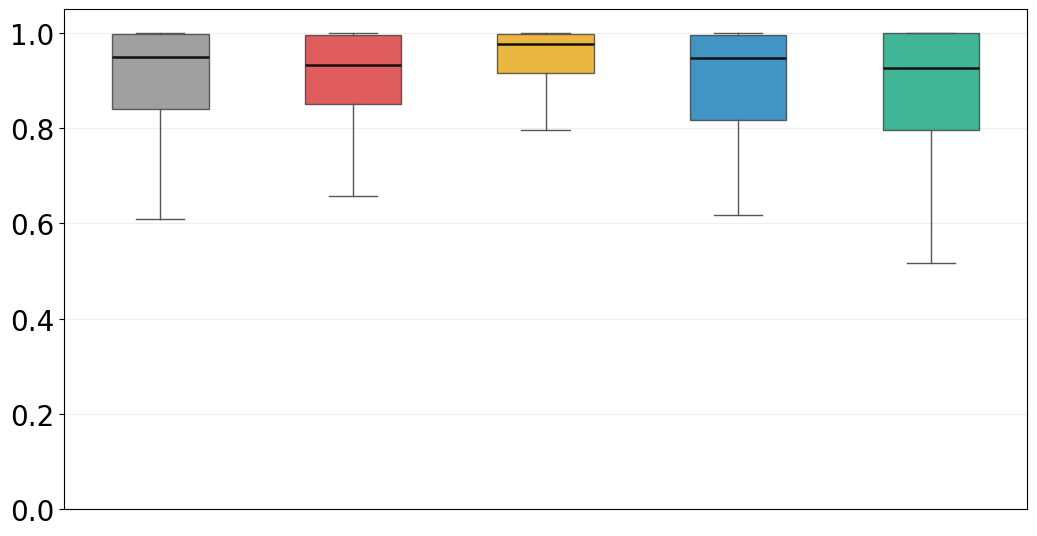

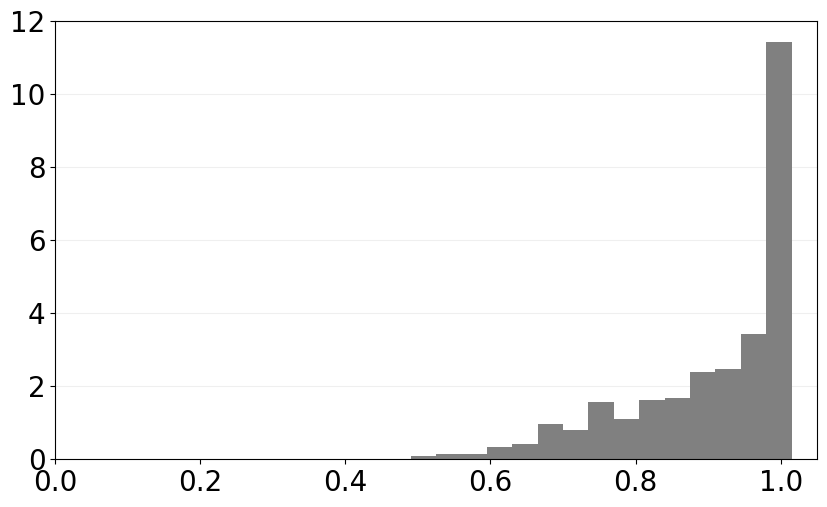

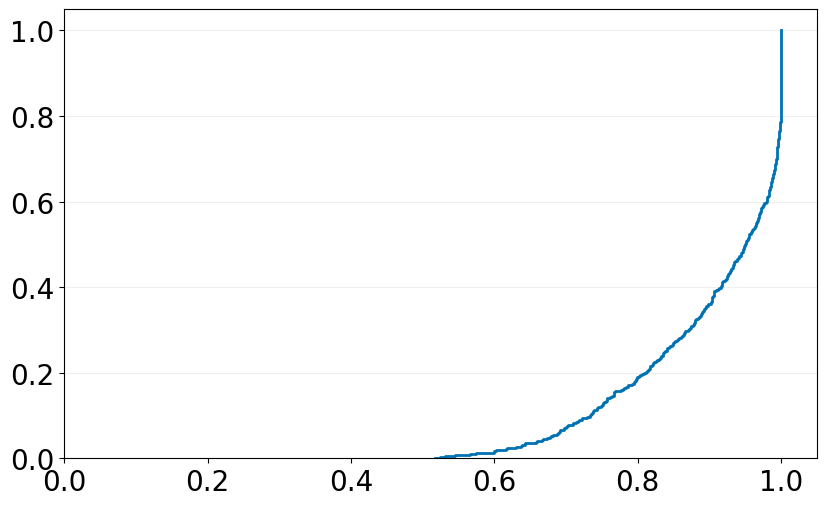

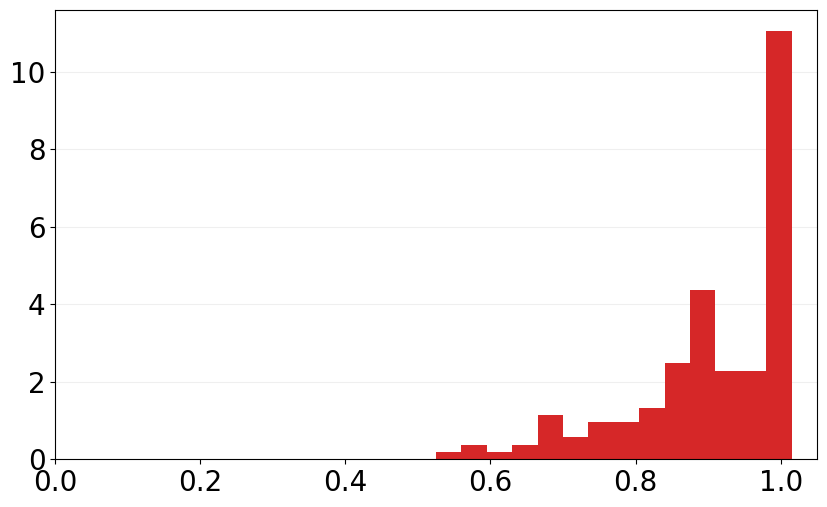

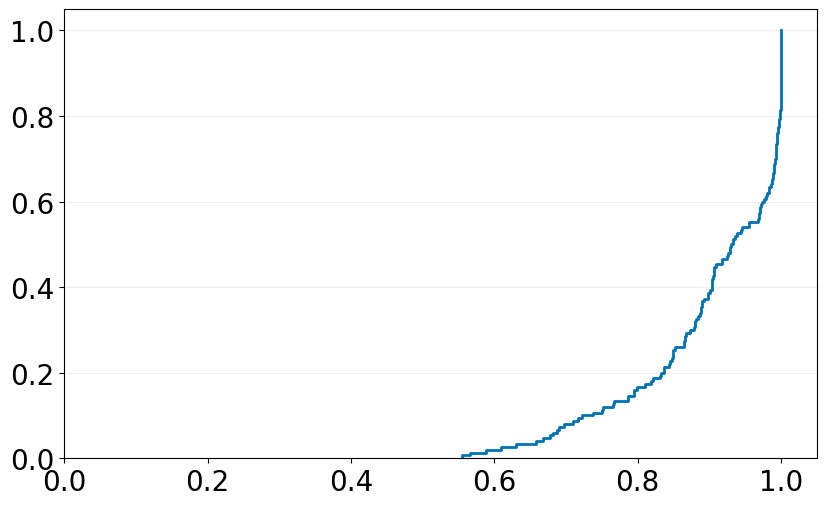

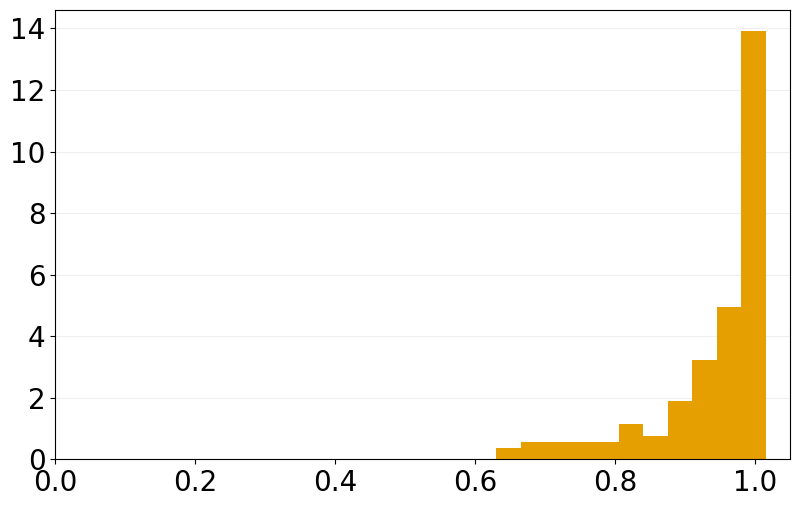

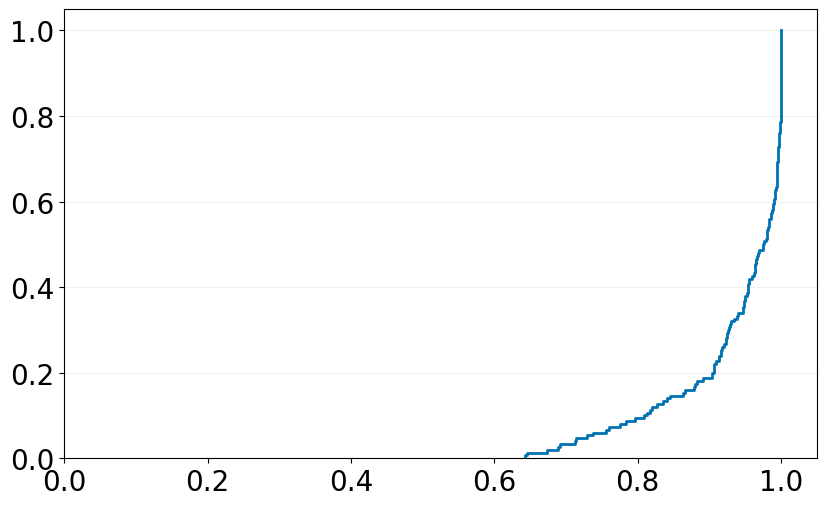

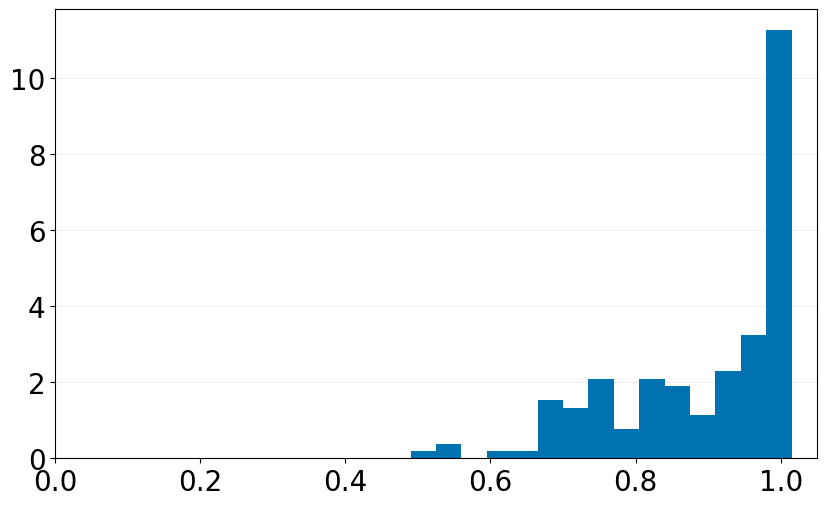

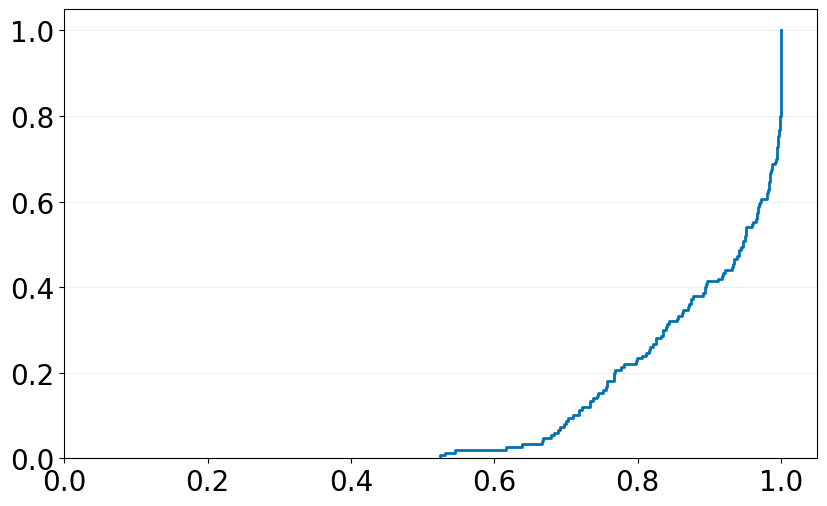

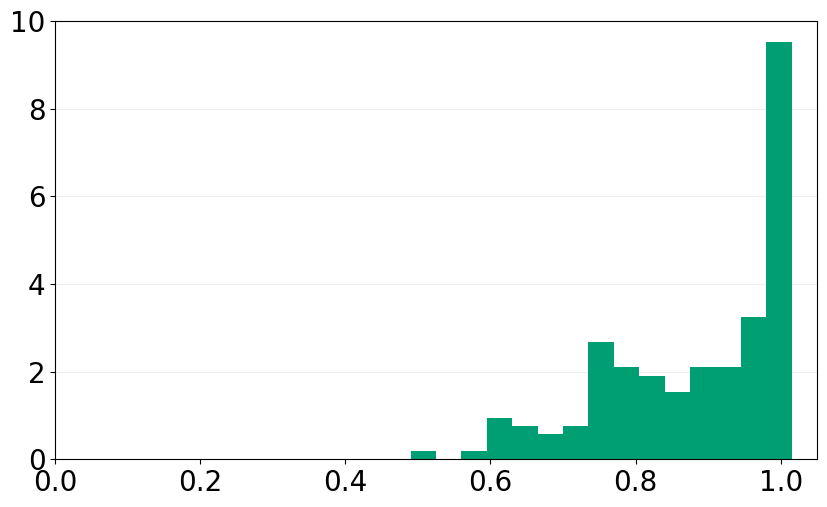

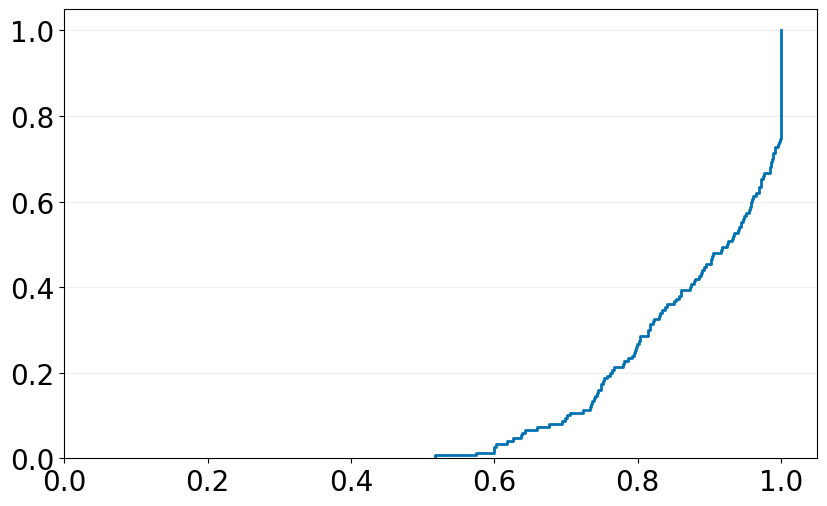

Creating zero-mean RMSE (rad) plots for Zero-lag correlation...


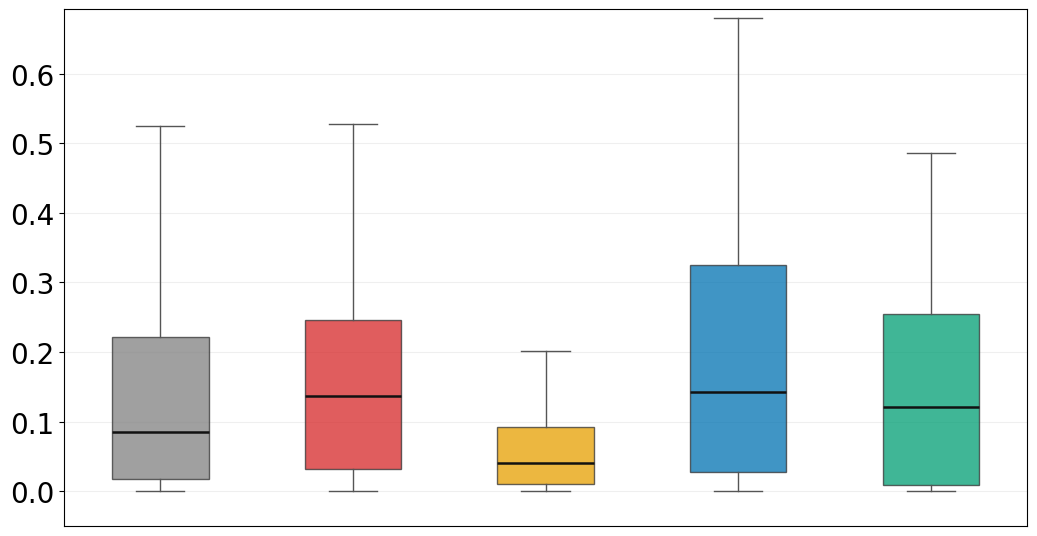

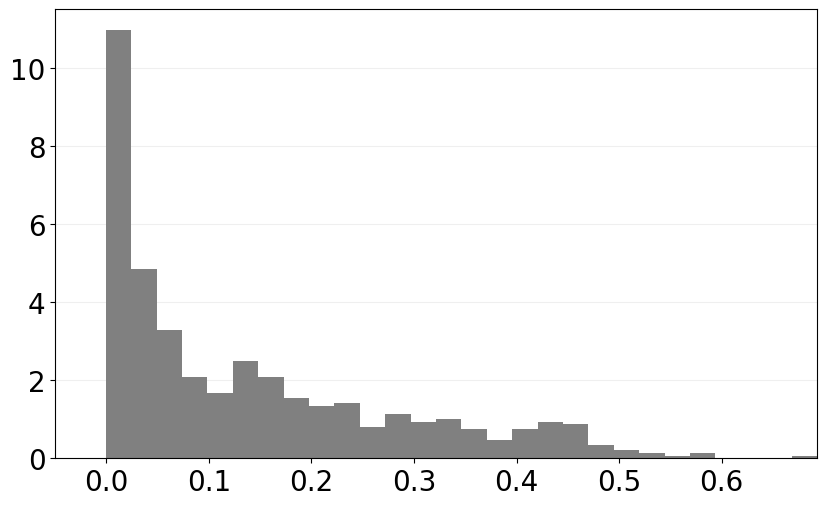

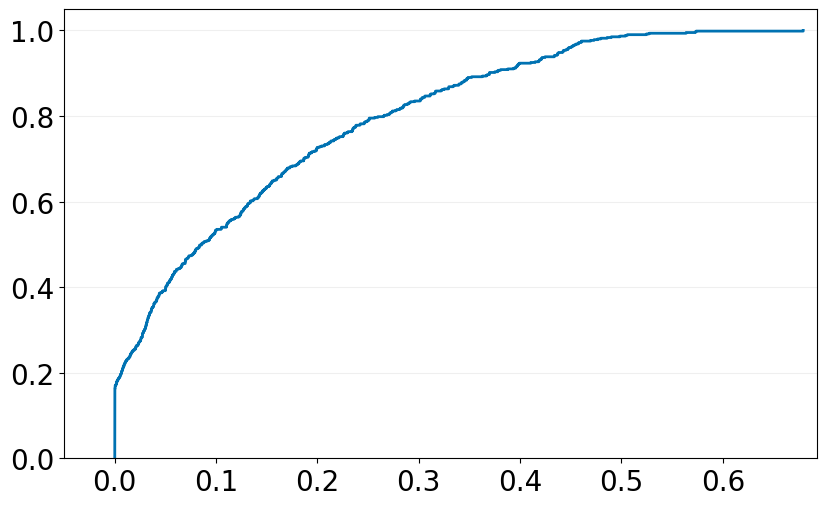

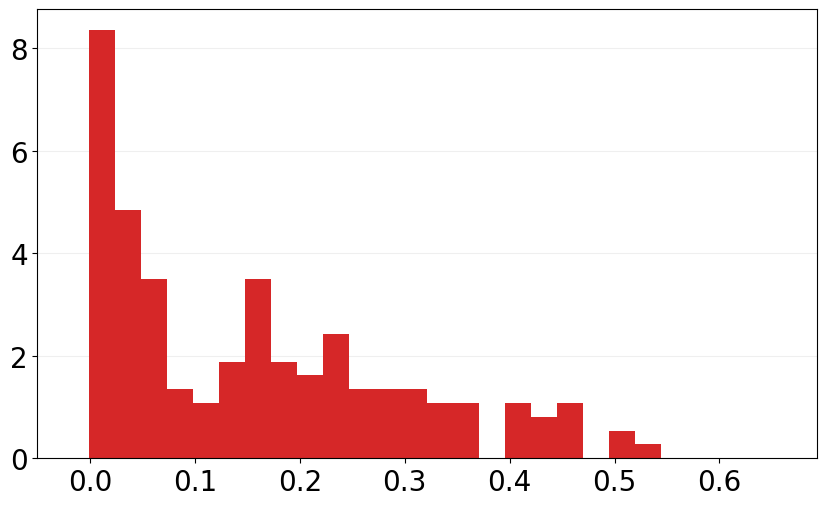

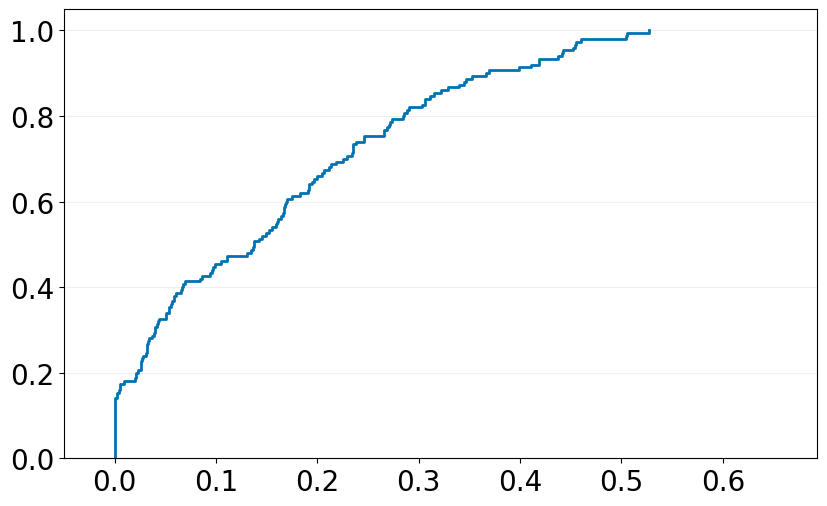

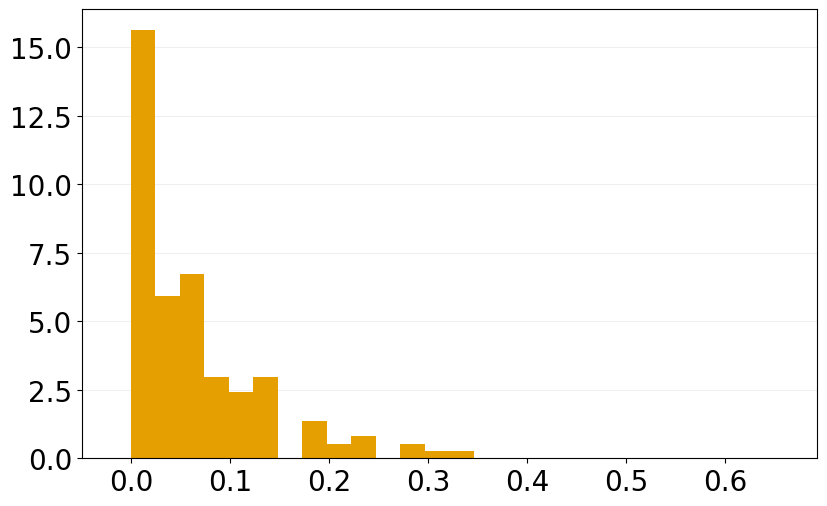

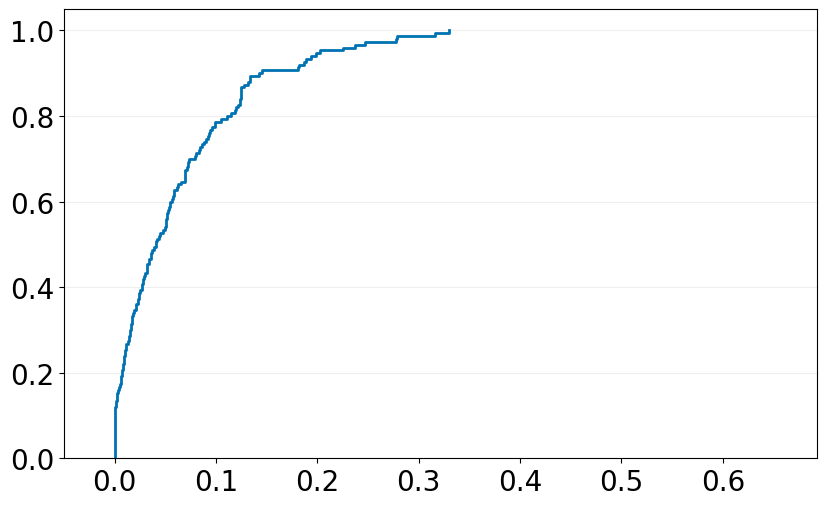

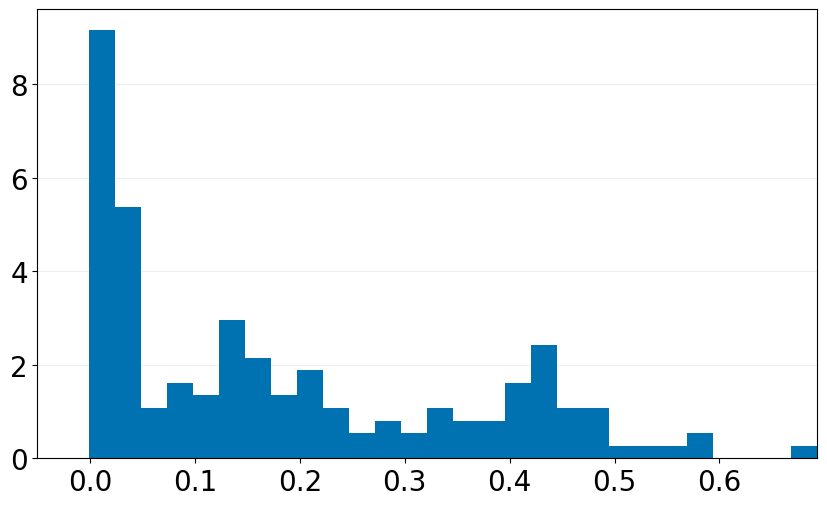

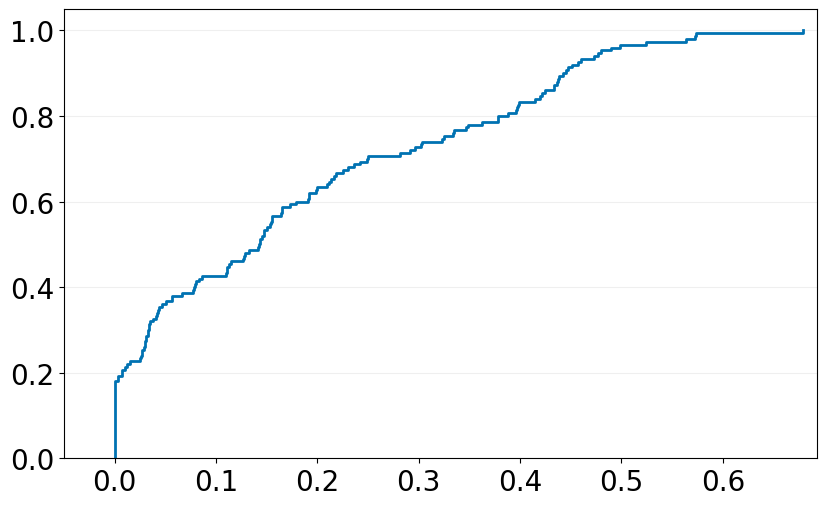

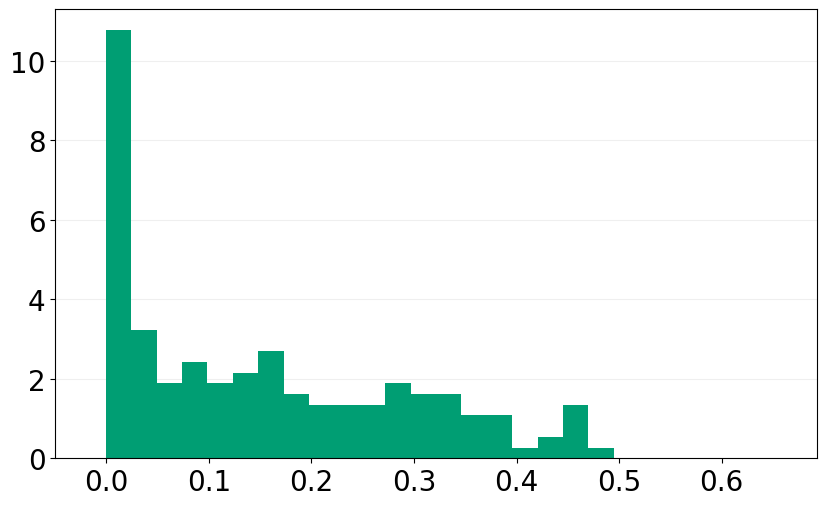

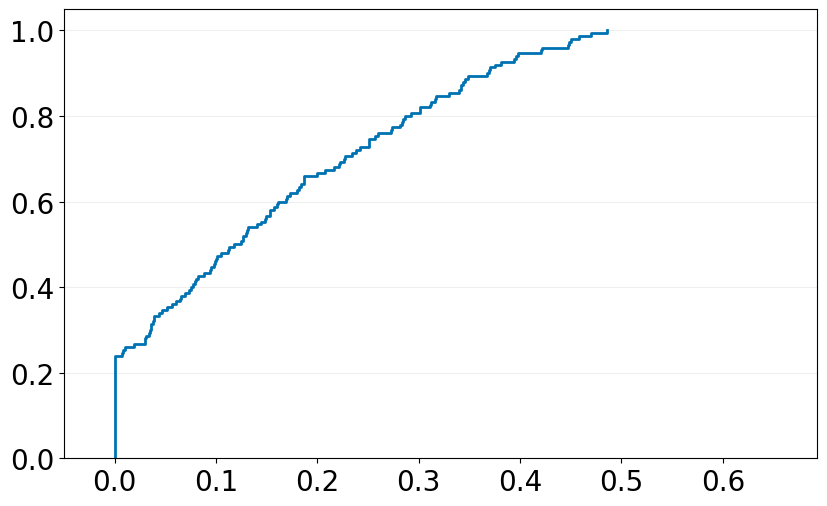

Generated 22 zero-mean figures.


In [59]:
zero_mean_plot_results = {}

for metric, spec in ZERO_MEAN_METRIC_SPECS.items():
    print(
        f'Creating zero-mean {spec["axis_label"]} plots for '
        f'{zero_mean_selected_loss_label}...'
    )
    all_metric_values = zero_mean_source_metrics[metric].to_numpy(dtype=float)
    metric_limits = zero_mean_metric_limits(all_metric_values, spec)
    metric_bin_edges = zero_mean_bin_edges(metric_limits, spec)

    metric_results = {
        'boxplot': plot_zero_mean_boxplot(
            zero_mean_source_metrics,
            metric,
            metric_limits,
        ),
        'distributions': {},
    }
    for scope, display_label, values in zero_mean_scope_groups(
        zero_mean_source_metrics,
        metric,
    ):
        metric_results['distributions'][f'{scope}_pdf'] = plot_zero_mean_pdf(
            values,
            metric,
            scope,
            display_label,
            metric_limits,
            metric_bin_edges,
        )
        metric_results['distributions'][f'{scope}_cdf'] = plot_zero_mean_cdf(
            values,
            metric,
            scope,
            display_label,
            metric_limits,
            metric_bin_edges,
        )

    zero_mean_plot_results[metric] = metric_results

zero_mean_generated_figure_count = sum(
    1 + len(results['distributions'])
    for results in zero_mean_plot_results.values()
)
print(f'Generated {zero_mean_generated_figure_count} zero-mean figures.')

### Selected-loss zero-mean distribution statistics

In [60]:
zero_mean_distribution_summary_rows = []

zero_mean_distribution_groups = [
    (OVERALL_LABEL, zero_mean_source_metrics),
] + [
    (
        FAMILY_LABELS[family],
        zero_mean_source_metrics.loc[
            zero_mean_source_metrics['family'] == family
        ],
    )
    for family in FAMILY_ORDER
]

for group_name, group_frame in zero_mean_distribution_groups:
    for metric, spec in ZERO_MEAN_METRIC_SPECS.items():
        value_series = group_frame[metric].dropna()
        zero_mean_distribution_summary_rows.append({
            'Group': group_name,
            'Metric': spec['axis_label'],
            'N': len(value_series),
            'Mean': value_series.mean(),
            'Standard deviation': value_series.std(ddof=1),
            'Skewness': value_series.skew(),
            'Kurtosis': value_series.kurt(),
        })

zero_mean_distribution_statistics_table = pd.DataFrame(
    zero_mean_distribution_summary_rows
)

display(
    zero_mean_distribution_statistics_table.style.format({
        'Mean': '{:.4f}',
        'Standard deviation': '{:.4f}',
        'Skewness': '{:.4f}',
        'Kurtosis': '{:.4f}',
    })
)

,Group,Metric,N,Mean,Standard deviation,Skewness,Kurtosis
0,Overall,Absolute correlation,600,0.9046,0.1115,-1.2049,0.6266
1,Overall,RMSE (rad),600,0.1377,0.1441,1.0513,0.1948
2,Harmonic,Absolute correlation,150,0.9041,0.1085,-1.2700,1.0101
3,Harmonic,RMSE (rad),150,0.1570,0.1426,0.7301,-0.4424
4,Filtered noise,Absolute correlation,150,0.9383,0.0850,-1.7907,2.5811
5,Filtered noise,RMSE (rad),150,0.0626,0.0691,1.6558,2.7926
6,Chirp modulated,Absolute correlation,150,0.8938,0.1194,-1.0409,0.2082
7,Chirp modulated,RMSE (rad),150,0.1806,0.1746,0.7224,-0.6638
8,Piecewise transient,Absolute correlation,150,0.8820,0.1225,-0.8475,-0.2617
9,Piecewise transient,RMSE (rad),150,0.1504,0.1408,0.6278,-0.7780


### Verify the selected-loss zero-mean outputs

In [23]:
zero_mean_expected_scopes = ('overall', *FAMILY_ORDER)
zero_mean_expected_distribution_keys = {
    f'{scope}_{plot_type}'
    for scope in zero_mean_expected_scopes
    for plot_type in ('pdf', 'cdf')
}
zero_mean_expected_group_sizes = (
    ZERO_MEAN_EXPECTED_TOTAL_OBSERVATIONS,
    *(
        ZERO_MEAN_EXPECTED_OBSERVATIONS_PER_FAMILY
        for _ in FAMILY_ORDER
    ),
)
zero_mean_expected_figure_count = len(ZERO_MEAN_METRIC_SPECS) * (
    1 + len(zero_mean_expected_distribution_keys)
)
zero_mean_expected_file_count = (
    zero_mean_expected_figure_count * len(ZERO_MEAN_EXPORT_FORMATS)
)
zero_mean_verification_rows = []
zero_mean_output_paths = []

for metric, metric_results in zero_mean_plot_results.items():
    spec = ZERO_MEAN_METRIC_SPECS[metric]
    box_result = metric_results['boxplot']
    if box_result['scopes'] != zero_mean_expected_scopes:
        raise AssertionError(
            f'{metric} box plot has unexpected scopes: '
            f'{box_result["scopes"]}'
        )
    if box_result['group_sizes'] != zero_mean_expected_group_sizes:
        raise AssertionError(
            f'{metric} box plot has unexpected group sizes: '
            f'{box_result["group_sizes"]}'
        )

    distributions = metric_results['distributions']
    if set(distributions) != zero_mean_expected_distribution_keys:
        raise AssertionError(
            f'{metric} is missing one or more zero-mean PDF/CDF variants'
        )
    reference_edges = distributions['overall_pdf']['bin_edges']
    reference_limits = distributions['overall_pdf']['limits']
    if len(reference_edges) != ZERO_MEAN_BIN_COUNT + 1:
        raise AssertionError(
            f'{metric} does not have the configured histogram bin count'
        )

    metric_output_paths = list(box_result['output_paths'])
    for plot_key, result in distributions.items():
        if not np.array_equal(result['bin_edges'], reference_edges):
            raise AssertionError(
                f'{metric}/{plot_key} does not use shared histogram bins'
            )
        if result['limits'] != reference_limits:
            raise AssertionError(
                f'{metric}/{plot_key} does not use shared metric limits'
            )
        expected_sample_count = (
            ZERO_MEAN_EXPECTED_TOTAL_OBSERVATIONS
            if result['scope'] == 'overall'
            else ZERO_MEAN_EXPECTED_OBSERVATIONS_PER_FAMILY
        )
        if result['sample_count'] != expected_sample_count:
            raise AssertionError(
                f'{metric}/{plot_key} has {result["sample_count"]} observations; '
                f'expected {expected_sample_count}'
            )
        metric_output_paths.extend(result['output_paths'])

    for output_path in metric_output_paths:
        zero_mean_output_paths.append(output_path)
        if not output_path.name.startswith(ZERO_MEAN_FILE_PREFIX):
            raise AssertionError(
                f'Output lacks collision-safe prefix: {output_path.name}'
            )
        if not output_path.is_file() or output_path.stat().st_size == 0:
            raise AssertionError(f'Missing or empty output: {output_path}')

    zero_mean_verification_rows.append({
        'metric': spec['axis_label'],
        'box_groups': len(box_result['group_sizes']),
        'distribution_figures': len(distributions),
        'histogram_bins': ZERO_MEAN_BIN_COUNT,
        'exports': len(metric_output_paths),
    })

if zero_mean_generated_figure_count != zero_mean_expected_figure_count:
    raise AssertionError(
        f'Generated {zero_mean_generated_figure_count} figures; '
        f'expected {zero_mean_expected_figure_count}'
    )
if len(zero_mean_output_paths) != zero_mean_expected_file_count:
    raise AssertionError(
        f'Generated {len(zero_mean_output_paths)} files; '
        f'expected {zero_mean_expected_file_count}'
    )
if len(set(zero_mean_output_paths)) != len(zero_mean_output_paths):
    raise AssertionError('Duplicate zero-mean output paths were generated')

zero_mean_expected_table_columns = [
    'Group',
    'Metric',
    'N',
    'Mean',
    'Standard deviation',
    'Skewness',
    'Kurtosis',
]
if list(zero_mean_distribution_statistics_table.columns) != (
    zero_mean_expected_table_columns
):
    raise AssertionError(
        'Zero-mean statistics table columns do not match the existing table'
    )
if zero_mean_distribution_statistics_table.shape != (
    len(ZERO_MEAN_METRIC_SPECS) * len(zero_mean_expected_scopes),
    len(zero_mean_expected_table_columns),
):
    raise AssertionError(
        'Zero-mean statistics table does not contain the expected 10 rows'
    )
zero_mean_expected_table_rows = [
    (group_label, spec['axis_label'])
    for group_label in (
        OVERALL_LABEL,
        *(FAMILY_LABELS[family] for family in FAMILY_ORDER),
    )
    for spec in ZERO_MEAN_METRIC_SPECS.values()
]
zero_mean_observed_table_rows = list(
    zero_mean_distribution_statistics_table[
        ['Group', 'Metric']
    ].itertuples(index=False, name=None)
)
if zero_mean_observed_table_rows != zero_mean_expected_table_rows:
    raise AssertionError(
        'Zero-mean statistics table has unexpected group/metric rows'
    )
zero_mean_expected_table_counts = [
    expected_count
    for expected_count in (
        ZERO_MEAN_EXPECTED_TOTAL_OBSERVATIONS,
        *(
            ZERO_MEAN_EXPECTED_OBSERVATIONS_PER_FAMILY
            for _ in FAMILY_ORDER
        ),
    )
    for _ in ZERO_MEAN_METRIC_SPECS
]
if zero_mean_distribution_statistics_table['N'].tolist() != (
    zero_mean_expected_table_counts
):
    raise AssertionError(
        'Zero-mean statistics table has unexpected sample counts'
    )
zero_mean_statistic_values = zero_mean_distribution_statistics_table[
    ['Mean', 'Standard deviation', 'Skewness', 'Kurtosis']
].to_numpy(dtype=float)
if not np.isfinite(zero_mean_statistic_values).all():
    raise AssertionError('Zero-mean statistics table contains non-finite values')

zero_mean_verification_table = pd.DataFrame(zero_mean_verification_rows)
display(zero_mean_verification_table)
print(
    f'Verified {len(zero_mean_source_metrics)} selected-loss observations, '
    f'{zero_mean_expected_figure_count} figures, and '
    f'{len(zero_mean_output_paths)} nonempty exports.'
)
print('Zero-mean figure output directory:', ZERO_MEAN_OUTPUT_DIR)

,metric,box_groups,distribution_figures,histogram_bins,exports
0,Absolute correlation,5,10,30,22
1,RMSE (rad),5,10,30,22


Verified 600 selected-loss observations, 22 figures, and 44 nonempty exports.
Zero-mean figure output directory: outputs/rss_formal_loss_comparison_zero_mean/plots
